# HIPOTESIS BIVARIADA PROPUESTA
## Hipótesis - El nivel de emision de CO2 en autos que utilizan combustion en ciclos urbanos , difiere segun el tipo de transmision utilizado.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from itertools import combinations

df = pd.read_excel("25-testcar-2026-01-21.xlsx")
data = df.copy()

#### Aqui nuevamente hay que comenzar limpiando el DataSet. En un principio hay que eliminar autos electricos o hibridos que no hayan sido sometidos a pruebas de combustion. (Electricity y Hydrogen 5) 

In [ ]:

valores_unicos = data[["Test Fuel Type Cd", "Test Fuel Type Description"]].drop_duplicates()

valores_unicos = valores_unicos.sort_values(by="Test Fuel Type Cd")

valores_unicos

,Test Fuel Type Cd,Test Fuel Type Description
1313,19,Federal Cert Diesel 7-15 PPM Sulfur
633,26,Cold CO Regular (Tier 2)
106,27,Cold CO Premium (Tier 2)
2461,28,Cold CO E10 Regular Gasoline (Tier 3)
1052,38,E85 (85% Ethanol 15% EPA Unleaded Gasoline)
2465,46,CARB LEV3 E10 Regular Gasoline
3021,47,CARB LEV3 E10 Premium Gasoline
2462,48,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)
1845,50,Hydrogen 5
0,61,Tier 2 Cert Gasoline


In [ ]:
data = data[(data["Test Fuel Type Cd"] != 50) & (data["Test Fuel Type Cd"] != 62)]

In [ ]:

valores_unicos = data[["Test Fuel Type Cd", "Test Fuel Type Description"]].drop_duplicates()

valores_unicos = valores_unicos.sort_values(by="Test Fuel Type Cd")

valores_unicos

,Test Fuel Type Cd,Test Fuel Type Description
1313,19,Federal Cert Diesel 7-15 PPM Sulfur
633,26,Cold CO Regular (Tier 2)
106,27,Cold CO Premium (Tier 2)
2461,28,Cold CO E10 Regular Gasoline (Tier 3)
1052,38,E85 (85% Ethanol 15% EPA Unleaded Gasoline)
2465,46,CARB LEV3 E10 Regular Gasoline
3021,47,CARB LEV3 E10 Premium Gasoline
2462,48,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)
0,61,Tier 2 Cert Gasoline


# HIPOTESIS BIVARIADA PROPUESTA
## Hipótesis - El nivel de emision de CO2 en autos que utilizan combustion en ciclos urbanos , difiere segun el tipo de transmision utilizado.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from itertools import combinations

df = pd.read_excel("25-testcar-2026-01-21.xlsx")
data = df.copy()

#### Aqui nuevamente hay que comenzar limpiando el DataSet. En un principio hay que eliminar autos electricos o hibridos que no hayan sido sometidos a pruebas de combustion. (Electricity y Hydrogen 5) 

In [ ]:

valores_unicos = data[["Test Fuel Type Cd", "Test Fuel Type Description"]].drop_duplicates()

valores_unicos = valores_unicos.sort_values(by="Test Fuel Type Cd")

valores_unicos

,Test Fuel Type Cd,Test Fuel Type Description
1313,19,Federal Cert Diesel 7-15 PPM Sulfur
633,26,Cold CO Regular (Tier 2)
106,27,Cold CO Premium (Tier 2)
2461,28,Cold CO E10 Regular Gasoline (Tier 3)
1052,38,E85 (85% Ethanol 15% EPA Unleaded Gasoline)
2465,46,CARB LEV3 E10 Regular Gasoline
3021,47,CARB LEV3 E10 Premium Gasoline
2462,48,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)
1845,50,Hydrogen 5
0,61,Tier 2 Cert Gasoline


In [ ]:
data = data[(data["Test Fuel Type Cd"] != 50) & (data["Test Fuel Type Cd"] != 62)]

In [ ]:

valores_unicos = data[["Test Fuel Type Cd", "Test Fuel Type Description"]].drop_duplicates()

valores_unicos = valores_unicos.sort_values(by="Test Fuel Type Cd")

valores_unicos

,Test Fuel Type Cd,Test Fuel Type Description
1313,19,Federal Cert Diesel 7-15 PPM Sulfur
633,26,Cold CO Regular (Tier 2)
106,27,Cold CO Premium (Tier 2)
2461,28,Cold CO E10 Regular Gasoline (Tier 3)
1052,38,E85 (85% Ethanol 15% EPA Unleaded Gasoline)
2465,46,CARB LEV3 E10 Regular Gasoline
3021,47,CARB LEV3 E10 Premium Gasoline
2462,48,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)
0,61,Tier 2 Cert Gasoline


## Ahora analicemos la columna de emision de CO2

In [ ]:
data["CO2 (g/mi)"].describe()

count    3493.000000
mean      310.325780
std       121.289408
min         0.000000
25%       220.174700
50%       279.936314
75%       379.027900
max      1093.643465
Name: CO2 (g/mi), dtype: float64

In [ ]:
co2_nan_count = data["CO2 (g/mi)"].isna().sum()
co2_zero_count = data["CO2 (g/mi)"].eq(0).sum()

print(f"NaN values: {co2_nan_count}")
print(f"Zero values: {co2_zero_count}")

casos_nulos = data[data["CO2 (g/mi)"].isna() | data["CO2 (g/mi)"].eq(0)]
casos_nulos = casos_nulos[["Test Fuel Type Cd", "Test Fuel Type Description", "CO2 (g/mi)",  "Test Procedure Description"]].drop_duplicates()
casos_nulos[["Test Fuel Type Cd", "Test Fuel Type Description",  "Test Procedure Description", "CO2 (g/mi)"]].sort_values(by=["Test Fuel Type Cd", "Test Procedure Description", "CO2 (g/mi)"])

NaN values: 130
Zero values: 1


,Test Fuel Type Cd,Test Fuel Type Description,Test Procedure Description,CO2 (g/mi)
3460,27,Cold CO Premium (Tier 2),Cold CO,0.0
108,61,Tier 2 Cert Gasoline,Charge Depleting Highway,NaN
107,61,Tier 2 Cert Gasoline,Charge Depleting UDDS,NaN


# Son estas combinaciones de tipo de test y combustibles todas aquellas que cuentan con valores 0 o NaN en la columna de CO2, investiguemos porque:

### - En el caso donde el procedimiento utilizado fue Cold CO, el valor de CO2 es 0.0 porque este procedimiento está diseñado específicamente para medir los niveles de Monóxido de arbono (CO) durante el arranque en frío a bajas temperaturas (típicamente 20°F). De esta manera lo mas probable es que como el test se centraba unicamente en este tipo de gas, se haya rellenado CO2 con 0 en representacion de un valor no valido o no medido.

- En los otros dos casos, los tipos de procedimientos de Charge Depleting corresponden a las fases de evaluación de vehículos híbridos enchufables (PHEV). Durante la fase "Charge Depleting", el vehículo se desplaza utilizando exclusivamente la energía de su batería eléctrica hasta que esta se agota. Aunque el vehículo contiene gasolina en el tanque ("Tier 2 Cert Gasoline"), el motor de combustión interna permanece apagado durante este ciclo, por lo que no genera ninguna emisión de CO2 en el escape para ser medida o registrada. De esta manera se justifica la ausencia de valores en dicha columna.

## Limpiemos finalmente estos valores

In [ ]:
data = data[(data["CO2 (g/mi)"] != 0.0) & (data["CO2 (g/mi)"].notna())]
co2_nan_count = data["CO2 (g/mi)"].isna().sum()
co2_zero_count = data["CO2 (g/mi)"].eq(0).sum()

print(f"NaN CO2 values: {co2_nan_count}")
print(f"Zero CO2 values: {co2_zero_count}")

NaN CO2 values: 0
Zero CO2 values: 0


### Ahora pasemos a explorar los distintos valores de CO2

In [ ]:
total_filas = len(data)
print(f"El total de filas es: {total_filas}")
data["CO2 (g/mi)"].describe()

El total de filas es: 3492


count    3492.000000
mean      310.414648
std       121.192990
min       106.938591
25%       220.227604
50%       279.963381
75%       379.031105
max      1093.643465
Name: CO2 (g/mi), dtype: float64

In [ ]:
outliers_CO2 = data[data["CO2 (g/mi)"] > 379.031105]
total_outliers_CO2 = len(outliers_CO2)
print(f"Total de outliers en CO2: {total_outliers_CO2}")

Total de outliers en CO2: 873


### El total de filas luego de eliminar electricos, hibridos no aplicables y nulos en C02 es de 3492. En cuanto a la informacion de CO2 se puede apreciar como la media es mayor a la mediana, eso y la enorme diferencia presente entre el maximo valor registrado de emision de CO2 y el quantil 3 pareceria indicar la presencia de outliers (y una distribucion asimetrica a derecha). Ademas, se aprecia como el desvio estandar tambien es alto, indicando mucha variabilidad entre los registros. Para continuar, primero analicemos los outliers utilizando la regla del rango intercuartilico (1.5* IQR) de Tukey

In [ ]:
cuantil_1 = data['CO2 (g/mi)'].quantile(0.25)
cuantil_3 = data['CO2 (g/mi)'].quantile(0.75)

iqr = cuantil_3 - cuantil_1

limite_inferior = cuantil_1 - 1.5 * iqr
limite_superior = cuantil_3 + 1.5 * iqr
print(f"El umbral superior estadístico calculado es: {limite_superior:.2f} MPG")
outliers_CO2 = data[data['CO2 (g/mi)'] > limite_superior].sort_values(by='CO2 (g/mi)', ascending=False)
outliers_CO2[["Veh Mfr Code" ,"Represented Test Veh Make", "Represented Test Veh Model", "CO2 (g/mi)", "Test Procedure Description"]].drop_duplicates().sort_values(by=["CO2 (g/mi)"], ascending=False)

El umbral superior estadístico calculado es: 617.24 MPG


,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,CO2 (g/mi),Test Procedure Description
357,BMX,BMW,M5 Sedan,1093.643465,SC03
371,BMX,BMW,M5 Touring,1057.074100,SC03
360,BMX,BMW,M5 Sedan,945.157600,Cold CO
4116,VGA,BUGATTI,Bugatti Pur Sport,935.000000,Federal fuel 2-day exhaust (w/can load)
372,BMX,BMW,M5 Touring,931.824900,Cold CO
492,BMX,BMW,XM Label,888.765003,Cold CO
368,BMX,BMW,M5 Touring,796.941800,Federal fuel 3-day exhaust
491,BMX,BMW,XM Label,795.786218,SC03
476,BMX,BMW,XM,783.277600,Federal fuel 3-day exhaust
478,BMX,BMW,XM,779.735719,SC03


In [ ]:
outliers_CO2[["Veh Mfr Code" ,"Represented Test Veh Make", "Represented Test Veh Model"]].drop_duplicates().sort_values(by=["Represented Test Veh Make"])

,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model
357,BMX,BMW,M5 Sedan
371,BMX,BMW,M5 Touring
492,BMX,BMW,XM Label
476,BMX,BMW,XM
440,BMX,BMW,X5 M Competition
4116,VGA,BUGATTI,Bugatti Pur Sport
4106,VGA,Bentley,Bentayga
1135,GMX,CADILLAC,ESCALADE V AWD
1126,GMX,CADILLAC,CT5 V
1482,GMX,CHEVROLET,SUBURBAN 4WD


### Investigando sobre todos aquellos vehiculos que superan el limite superior planteado nos encontramos con dos grupos bien marcados: 

Grupo 1: superdeportivos y autos de lujo/alto rendimiento:
    - Bugatti Pur Sport, Bentley Bentayga, Lamborghini Revuelto, Pagani Utopia, Ferrari F175 AHA.
    - BMW M5 Sedan, M5 Touring, XM, X5 M Competition.
    - Chevrolet Corvette ZR1 y Z06 (incluida la Carbon Aero), Cadillac CT5-V, Mustang GTD, Dodge Durango SRT

    Son motores grandes (V8, V12, W16), con mucha potencia, turbo o sobrealimentación, y mucho peso en el caso de los SUV de lujo. Más potencia y más consumo de combustible implican más CO2.

Grupo 2: camionetas y SUV grandes, de trabajo o todo terreno

    -Chevrolet Suburban 4WD, Cadillac Escalade V, GMC Sierra 4WD (varias versiones, incluida la Cab Chassis), Ford F150 Raptor R, INEOS Grenadier
    En este caso nos enontramos con vehiculos grandes y potentes, gran tamaño, mucho peso, tracción 4x4 y motores V8 grandes. Una Suburban o una Sierra pueden emitir tanto o más CO2 que varios deportivos.

### Dada esta situacion, se decidio eliminar estos casos del analisis. La hipotesis planteada busca que se pueda investigar y decidir cual es la mejor eleccion de trasmision si se quiere minimizar la emision de CO2, o poder plantear nuevos criterios de evaluacion en niveles de emision segun tipo de transmision. En busca de que estos resultados sean mas representativos, se eliminan casos excepcionales de autos de altisimo consumo (que ademas son muy caros!) que son alta minoria en las calles en el dia a dia.

### Finalmente nos queda:

In [ ]:
data = data[(data['CO2 (g/mi)'] <= limite_superior)]
total_filas = len(data)
print(f"El total de filas es: {total_filas}")
data["CO2 (g/mi)"].describe()


El total de filas es: 3424


count    3424.000000
mean      302.572436
std       107.848626
min       106.938591
25%       218.928750
50%       277.064000
75%       373.924913
max       613.666000
Name: CO2 (g/mi), dtype: float64

## Analisis exploratorio general

In [ ]:
unics = data[["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #"]].drop_duplicates()
length = len(unics)
print(f"El total de combinaciones únicas de Veh Mfr Code, Test Vehicle ID y Test Veh Configuration # es: {length}")

prueba = data[data["Test Vehicle ID"] == "8D89453"]
prueba[["Test Procedure Description", "Test Fuel Type Cd", "Test Category", "RND_ADJ_FE", "CO2 (g/mi)"]].sort_values(by=["Test Procedure Description", "Test Fuel Type Cd", "Test Category"])

El total de combinaciones únicas de Veh Mfr Code, Test Vehicle ID y Test Veh Configuration # es: 1091


,Test Procedure Description,Test Fuel Type Cd,Test Category,RND_ADJ_FE,CO2 (g/mi)
12,Federal fuel 3-day exhaust,61,FTP,36.2,241.3423
13,Federal fuel 3-day exhaust,61,FTP,36.2,241.3423
16,Federal fuel 3-day exhaust,61,FTP,33.7,259.2078
17,Federal fuel 3-day exhaust,61,FTP,33.7,259.2078
14,HWFE,61,HWY,51.6,169.1714
15,HWFE,61,HWY,51.6,169.1714
18,HWFE,61,HWY,47.2,184.5822
19,HWFE,61,HWY,47.2,184.5822



### Continuando, nos quedemonos solo con los vehiculos que llevan a cabo ciclos de ciudad (se podria haber hecho antes), con el objetivo de dar unos resultados que se asocien al uso mas cotidiano para todos los vehiculos, y mas teniendo en cuenta que el control de emision de gases es mas importante principalmente en areas urbanas.     


In [ ]:
data = data[data["Test Category"] == "FTP"]
leng = len(data)
print(f"El total de filas con Test Category 'FTP' es: {leng}")

El total de filas con Test Category 'FTP' es: 1505


### Por ultimo, el analisis exploratorio del DataSet denoto la no independencia de nuestros datos para poder llevar a cabo el test de hipotesis, ¿por que? Dado que en este mismo se hayan multiples filas sobre una misma configuracion de vehiculo para un ensayo FTP, identificado por Veh Mfr Code, Test Vehicle ID y Test Veh Configuration #. ¿Porque se da esto? Variaciones en el combustible utilizado o el tratamiento sobre el escape pueden ser las razones de multiples ensayos identicos sobre un mismo vehiculo, o hay casos donde directamente no hay variacion en el vehiculo y ensayo, si no que simplemente cambian los valores del test, ejemplo: [Veh Mfr Code:VGA, Test Vehicle ID:VW316550199, Test Veh Configuration #:0]. De esta manera, para poder garantizar independencia entre las observaciones se decidio agrupar por Veh Mfr Code, Test Vehicle ID y Test Veh Configuration, colapsando los valores de emision de CO2, en caso de haber varios, a un unico por vehiculo utilizando la mediana. 


In [ ]:
mascara = data.duplicated(subset=["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Tested Transmission Type"], keep=False)

filas_repetidas = data[mascara]
filas_repetidas[["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Tested Transmission Type", "CO2 (g/mi)", "Test Fuel Type Description", "Aftertreatment Device Cd"]]


,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,Tested Transmission Type,CO2 (g/mi),Test Fuel Type Description,Aftertreatment Device Cd
12,BMX,8D89453,0,Semi-Automatic,241.342300,Tier 2 Cert Gasoline,OT
13,BMX,8D89453,0,Semi-Automatic,241.342300,Tier 2 Cert Gasoline,TWC
16,BMX,8D89453,1,Semi-Automatic,259.207800,Tier 2 Cert Gasoline,TWC
17,BMX,8D89453,1,Semi-Automatic,259.207800,Tier 2 Cert Gasoline,OT
20,BMX,8D89454,0,Semi-Automatic,253.719000,Tier 2 Cert Gasoline,TWC
...,...,...,...,...,...,...,...
4153,VGA,VW38004-0068,0,Automated Manual- Selectable (e.g. Automated M...,316.000000,Tier 2 Cert Gasoline,TWC
4186,VGA,VW316550199,0,Semi-Automatic,273.611011,Tier 2 Cert Gasoline,TWC
4188,VGA,VW316550199,0,Semi-Automatic,274.576617,Tier 2 Cert Gasoline,TWC
4249,VVX,202520,0,Semi-Automatic,299.429199,Tier 2 Cert Gasoline,TWC


In [ ]:
data = data.groupby(["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Tested Transmission Type"])["CO2 (g/mi)"].median().reset_index()

### Ahora si, empecemos a desarrollar

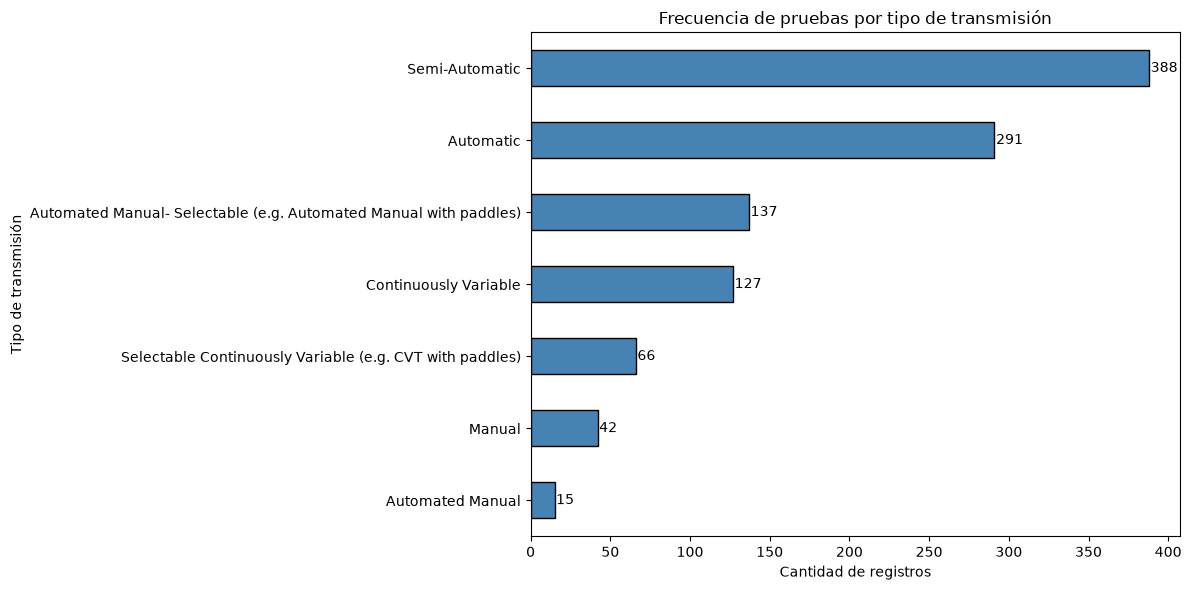

In [ ]:
frecuencia_combustibles = data["Tested Transmission Type"].value_counts().sort_values(ascending=True)

plt.figure(figsize=(12, 6))
ax = frecuencia_combustibles.plot(
    kind="barh",
    color="steelblue",
    edgecolor="black"
)

ax.set_title("Frecuencia de pruebas por tipo de transmisión")
ax.set_xlabel("Cantidad de registros")
ax.set_ylabel("Tipo de transmisión")

for i, valor in enumerate(frecuencia_combustibles):
    ax.text(valor + 1, i, str(valor), va="center")

plt.tight_layout()
plt.show()



### Podemos apreciar como automated-manual cuenta con un numero muy chico de muestras, un grupo con un N tan chico no es lo suficientemente representativa de la poblacion y por lo tanto poco confiable, de esta manera se decide excluirlo de la hipotesis.

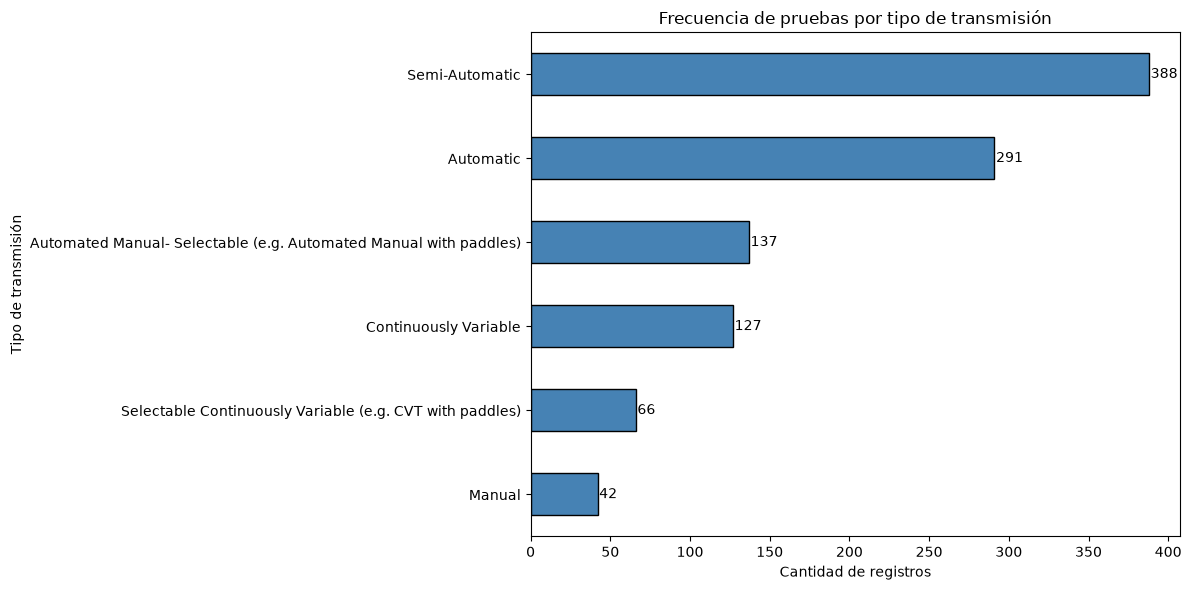

In [ ]:
data = data[data["Tested Transmission Type"] != "Automated Manual"]
frecuencia_combustibles = data["Tested Transmission Type"].value_counts().sort_values(ascending=True)

plt.figure(figsize=(12, 6))
ax = frecuencia_combustibles.plot(
    kind="barh",
    color="steelblue",
    edgecolor="black"
)

ax.set_title("Frecuencia de pruebas por tipo de transmisión")
ax.set_xlabel("Cantidad de registros")
ax.set_ylabel("Tipo de transmisión")

for i, valor in enumerate(frecuencia_combustibles):
    ax.text(valor + 1, i, str(valor), va="center")

plt.tight_layout()
plt.show()


### Ahora realicemos BoxPlots  para observar como se comporta la emision de CO2 segun el tipo de transmision

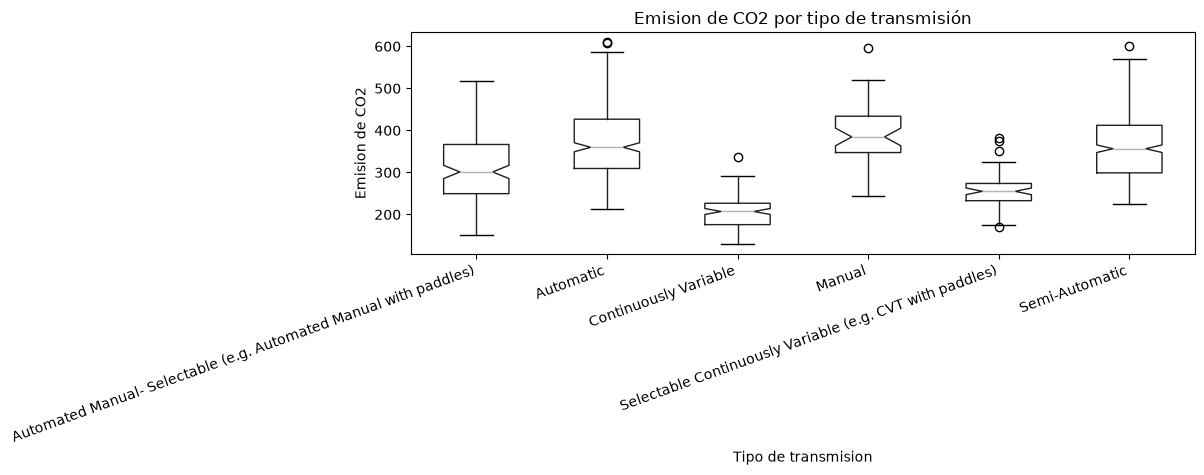

In [ ]:
ax = data.boxplot(
    column="CO2 (g/mi)",
    by="Tested Transmission Type",
    figsize=(12, 5),
    grid=False,
    notch=True
)

ax.set_title("Emision de CO2 por tipo de transmisión")
ax.set_xlabel("Tipo de transmision")
ax.set_ylabel("Emision de CO2")
plt.suptitle("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### El boxplot nos muestra que las transmisiones Continuously Variable (mediana cercana a 200 g/mi) y Selectable Continuously Variable (cercana a 250 g/mi) tienen las emisiones más bajas y la menor dispersión. Automated Manual- Selectable ocupa una posición intermedia (alrededor de 300 g/mi), mientras que Semi-Automatic, Automatic y Manual presentan los valores más altos (entre 350 y 400 g/mi aproximadamente) y una mayor variabilidad. Se observan además algunos valores atípicos en la parte superior de varias categorías.

### Las muecas no parecen coincidir entre si, salvo semi-automatic y automatic que se aproximan mucho tambien en su distribucion. En un principio todo pareceria indicar que hay diferencias significativas entre las emisiones de CO2 entre los distintos tipos de transmisiones. Pero hay que probarlo.

## PASOS:
### Dado que nos aseguramos independencia entre las variables, con mas de dos grupos nuestras opciones para llevar a cabo el test de hipotesis son Anova o Kruskall-Wallis.
### Para el primero sera necesario cumplir sus supuestos por lo que procederemos a comprobarlos
### -Normalidad (Shapiro-Wilks/QQ-plot) -> Si no se cumple se pasara directamente a Kruskall-Wallis
### -Homocedasticidad (Levene)

In [ ]:
from scipy.stats import shapiro

# Separamos los datos en dos grupos, desarrollados y en vías de desarrollo
automatic_CO2 = data[data["Tested Transmission Type"] == "Automatic"]['CO2 (g/mi)']
manual_CO2 = data[data["Tested Transmission Type"] == "Manual"]['CO2 (g/mi)']
semi_auto_CO2 = data[data["Tested Transmission Type"] == "Semi-Automatic"]['CO2 (g/mi)']
scv_wp_CO2 = data[data["Tested Transmission Type"] == "Selectable Continuously Variable (e.g. CVT with paddles)"]['CO2 (g/mi)']
auto_manual_C02 = data[data["Tested Transmission Type"] == "Automated Manual- Selectable (e.g. Automated Manual with paddles)"]['CO2 (g/mi)']
con_var_CO2 = data[data["Tested Transmission Type"] == "Continuously Variable"]['CO2 (g/mi)']
# Test de Shapiro-Wilk para países desarrollados
stat, p = shapiro(automatic_CO2)
print(f"Automatic:\t\t Estadístico = {stat:.4f}, p-valor = {p:.4g}")

stat, p = shapiro(manual_CO2)
print(f"Manual:\t\t\t Estadístico = {stat:.4f}, p-valor = {p:.4g}")

stat, p = shapiro(semi_auto_CO2)
print(f"Semi-automatic:\t\t Estadístico = {stat:.4f}, p-valor = {p:.4g}")

stat, p = shapiro(scv_wp_CO2)
print(f"Selectable CVT:\t\t Estadístico = {stat:.4f}, p-valor = {p:.4g}")

stat, p = shapiro(auto_manual_C02)
print(f"Automated Manual:\t Estadístico = {stat:.4f}, p-valor = {p:.4g}")

stat, p = shapiro(con_var_CO2)
print(f"Continuously Variable:\t Estadístico = {stat:.4f}, p-valor = {p:.4g}")


Automatic:		 Estadístico = 0.9643, p-valor = 1.333e-06
Manual:			 Estadístico = 0.9731, p-valor = 0.4158
Semi-automatic:		 Estadístico = 0.9695, p-valor = 3.03e-07
Selectable CVT:		 Estadístico = 0.9576, p-valor = 0.0242
Automated Manual:	 Estadístico = 0.9775, p-valor = 0.02287
Continuously Variable:	 Estadístico = 0.9732, p-valor = 0.01275


### Como se puede observar por los p-valores la gran mayoria no se distribuye normalmente, por lo que no se puede proceder a realizar un test de ANOVA sobre los datos y se tendra que recurrir a un Kruskall-wallis. Remarcar aun asi que los tipos de transmisiones manuales si se distribuyen normalmente respecto a su emision de CO2, tambien no es sorpresa que sea el que menor numero de muestras tenia de todas las categorias. De igual manera observemos los QQ-PLOT a continuacion.

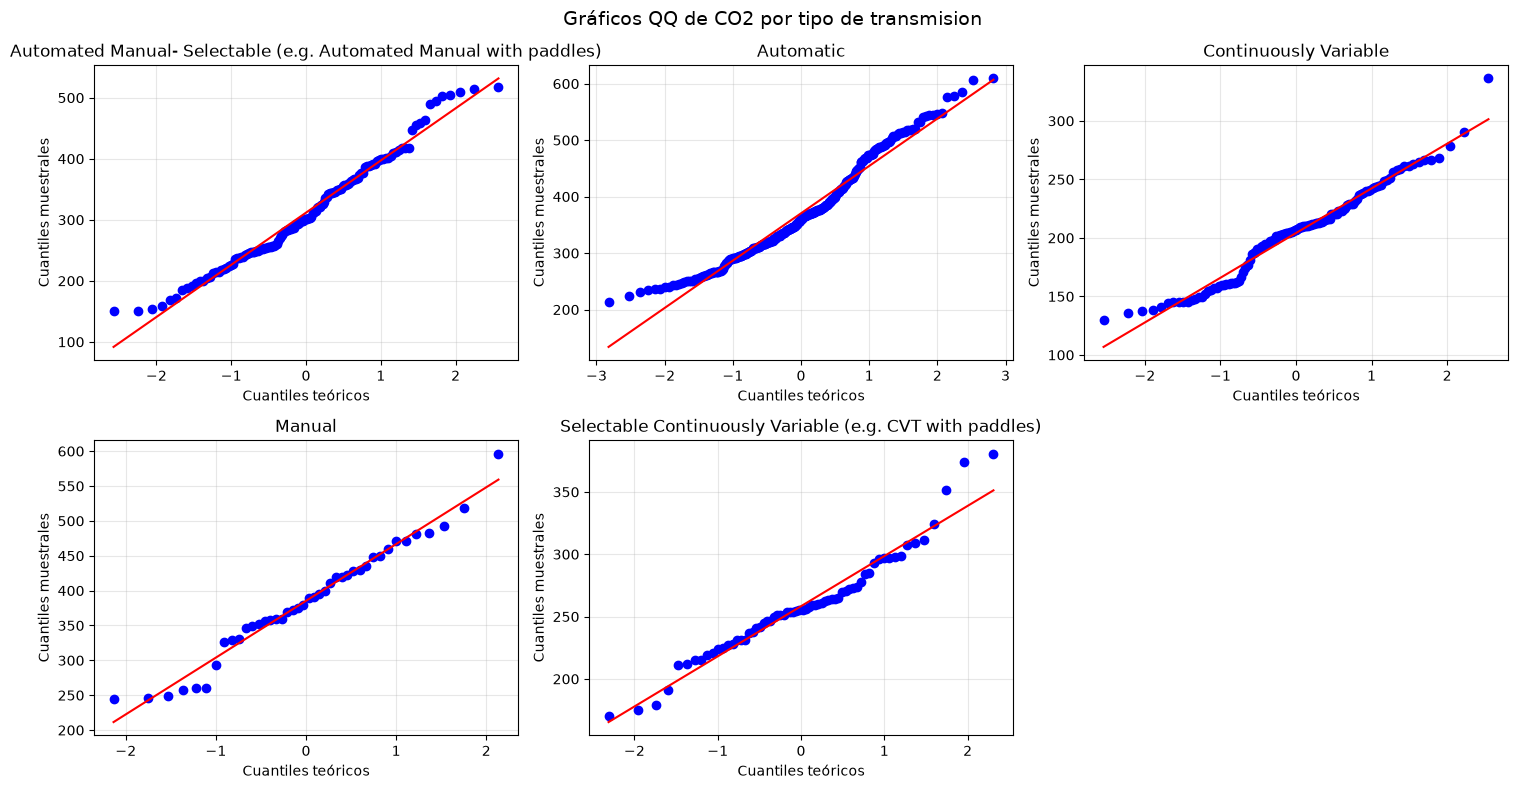

In [ ]:
from scipy import stats

import matplotlib.pyplot as plt

grupos = data.groupby("Tested Transmission Type")["CO2 (g/mi)"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax_qq, (traccion, valores) in zip(axes, grupos):
    valores = valores.dropna()
    stats.probplot(valores, dist="norm", plot=ax_qq)
    ax_qq.set_title(traccion)
    ax_qq.set_xlabel("Cuantiles teóricos")
    ax_qq.set_ylabel("Cuantiles muestrales")
    ax_qq.grid(alpha=0.3)

axes[-1].set_visible(False)
fig.suptitle("Gráficos QQ de CO2 por tipo de transmision", fontsize=14)
plt.tight_layout()
plt.show()

### Finalmente como no se cumplieron los supuestos necesarios para realizar ANOVA, procederemos a llevar a cabo Kruskall-Wallis

In [ ]:
stat, p = stats.kruskal(automatic_CO2, manual_CO2, semi_auto_CO2, scv_wp_CO2, auto_manual_C02, con_var_CO2)
alpha = 0.05  # Nivel de significancia
print(f"Test de Kruskal-Wallis para CO2 (g/mi) entre transmisiones: Estadístico={stat:.3f}, p-valor={p:.3f}")
if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en la emision de CO2 segun el tipo de transmision")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en la emision de CO2 segun el tipo de transmision")

Test de Kruskal-Wallis para CO2 (g/mi) entre transmisiones: Estadístico=404.267, p-valor=0.000
Se rechaza la hipótesis nula.
Existe una diferencia significativa en la emision de CO2 segun el tipo de transmision


# CONCLUSION:
## El p-valor < 0.05 indica que existe evidencia estadistica suficiente para rechazar la hipotesis nula (H0). Esto puede afirmar la hipotesis alternativa(H1). De esta manera se puede afirmar, que efectivamente, existen diferencias en la emision de CO2 entre los vehiculos a combustion en ciclos urbanos.

---

## Ahora analicemos la columna de emision de CO2

In [ ]:
data["CO2 (g/mi)"].describe()

count    3493.000000
mean      310.325780
std       121.289408
min         0.000000
25%       220.174700
50%       279.936314
75%       379.027900
max      1093.643465
Name: CO2 (g/mi), dtype: float64

In [ ]:
co2_nan_count = data["CO2 (g/mi)"].isna().sum()
co2_zero_count = data["CO2 (g/mi)"].eq(0).sum()

print(f"NaN values: {co2_nan_count}")
print(f"Zero values: {co2_zero_count}")

casos_nulos = data[data["CO2 (g/mi)"].isna() | data["CO2 (g/mi)"].eq(0)]
casos_nulos = casos_nulos[["Test Fuel Type Cd", "Test Fuel Type Description", "CO2 (g/mi)",  "Test Procedure Description"]].drop_duplicates()
casos_nulos[["Test Fuel Type Cd", "Test Fuel Type Description",  "Test Procedure Description", "CO2 (g/mi)"]].sort_values(by=["Test Fuel Type Cd", "Test Procedure Description", "CO2 (g/mi)"])

NaN values: 130
Zero values: 1


,Test Fuel Type Cd,Test Fuel Type Description,Test Procedure Description,CO2 (g/mi)
3460,27,Cold CO Premium (Tier 2),Cold CO,0.0
108,61,Tier 2 Cert Gasoline,Charge Depleting Highway,NaN
107,61,Tier 2 Cert Gasoline,Charge Depleting UDDS,NaN


# Son estas combinaciones de tipo de test y combustibles todas aquellas que cuentan con valores 0 o NaN en la columna de CO2, investiguemos porque:

### - En el caso donde el procedimiento utilizado fue Cold CO, el valor de CO2 es 0.0 porque este procedimiento está diseñado específicamente para medir los niveles de Monóxido de arbono (CO) durante el arranque en frío a bajas temperaturas (típicamente 20°F). De esta manera lo mas probable es que como el test se centraba unicamente en este tipo de gas, se haya rellenado CO2 con 0 en representacion de un valor no valido o no medido.

- En los otros dos casos, los tipos de procedimientos de Charge Depleting corresponden a las fases de evaluación de vehículos híbridos enchufables (PHEV). Durante la fase "Charge Depleting", el vehículo se desplaza utilizando exclusivamente la energía de su batería eléctrica hasta que esta se agota. Aunque el vehículo contiene gasolina en el tanque ("Tier 2 Cert Gasoline"), el motor de combustión interna permanece apagado durante este ciclo, por lo que no genera ninguna emisión de CO2 en el escape para ser medida o registrada. De esta manera se justifica la ausencia de valores en dicha columna.

## Limpiemos finalmente estos valores

In [ ]:
data = data[(data["CO2 (g/mi)"] != 0.0) & (data["CO2 (g/mi)"].notna())]
co2_nan_count = data["CO2 (g/mi)"].isna().sum()
co2_zero_count = data["CO2 (g/mi)"].eq(0).sum()

print(f"NaN CO2 values: {co2_nan_count}")
print(f"Zero CO2 values: {co2_zero_count}")

NaN CO2 values: 0
Zero CO2 values: 0


### Ahora pasemos a explorar los distintos valores de CO2

In [ ]:
total_filas = len(data)
print(f"El total de filas es: {total_filas}")
data["CO2 (g/mi)"].describe()

El total de filas es: 3492


count    3492.000000
mean      310.414648
std       121.192990
min       106.938591
25%       220.227604
50%       279.963381
75%       379.031105
max      1093.643465
Name: CO2 (g/mi), dtype: float64

In [ ]:
outliers_CO2 = data[data["CO2 (g/mi)"] > 379.031105]
total_outliers_CO2 = len(outliers_CO2)
print(f"Total de outliers en CO2: {total_outliers_CO2}")

Total de outliers en CO2: 873


### El total de filas luego de eliminar electricos, hibridos no aplicables y nulos en C02 es de 3492. En cuanto a la informacion de CO2 se puede apreciar como la media es mayor a la mediana, eso y la enorme diferencia presente entre el maximo valor registrado de emision de CO2 y el quantil 3 pareceria indicar la presencia de outliers (y una distribucion asimetrica a derecha). Ademas, se aprecia como el desvio estandar tambien es alto, indicando mucha variabilidad entre los registros. Para continuar, primero analicemos los outliers utilizando la regla del rango intercuartilico (1.5* IQR) de Tukey

In [ ]:
cuantil_1 = data['CO2 (g/mi)'].quantile(0.25)
cuantil_3 = data['CO2 (g/mi)'].quantile(0.75)

iqr = cuantil_3 - cuantil_1

limite_inferior = cuantil_1 - 1.5 * iqr
limite_superior = cuantil_3 + 1.5 * iqr
print(f"El umbral superior estadístico calculado es: {limite_superior:.2f} MPG")
outliers_CO2 = data[data['CO2 (g/mi)'] > limite_superior].sort_values(by='CO2 (g/mi)', ascending=False)
outliers_CO2[["Veh Mfr Code" ,"Represented Test Veh Make", "Represented Test Veh Model", "CO2 (g/mi)", "Test Procedure Description"]].drop_duplicates().sort_values(by=["CO2 (g/mi)"], ascending=False)

El umbral superior estadístico calculado es: 617.24 MPG


,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,CO2 (g/mi),Test Procedure Description
357,BMX,BMW,M5 Sedan,1093.643465,SC03
371,BMX,BMW,M5 Touring,1057.074100,SC03
360,BMX,BMW,M5 Sedan,945.157600,Cold CO
4116,VGA,BUGATTI,Bugatti Pur Sport,935.000000,Federal fuel 2-day exhaust (w/can load)
372,BMX,BMW,M5 Touring,931.824900,Cold CO
492,BMX,BMW,XM Label,888.765003,Cold CO
368,BMX,BMW,M5 Touring,796.941800,Federal fuel 3-day exhaust
491,BMX,BMW,XM Label,795.786218,SC03
476,BMX,BMW,XM,783.277600,Federal fuel 3-day exhaust
478,BMX,BMW,XM,779.735719,SC03


In [ ]:
outliers_CO2[["Veh Mfr Code" ,"Represented Test Veh Make", "Represented Test Veh Model"]].drop_duplicates().sort_values(by=["Represented Test Veh Make"])

,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model
357,BMX,BMW,M5 Sedan
371,BMX,BMW,M5 Touring
492,BMX,BMW,XM Label
476,BMX,BMW,XM
440,BMX,BMW,X5 M Competition
4116,VGA,BUGATTI,Bugatti Pur Sport
4106,VGA,Bentley,Bentayga
1135,GMX,CADILLAC,ESCALADE V AWD
1126,GMX,CADILLAC,CT5 V
1482,GMX,CHEVROLET,SUBURBAN 4WD


### Investigando sobre todos aquellos vehiculos que superan el limite superior planteado nos encontramos con dos grupos bien marcados: 

Grupo 1: superdeportivos y autos de lujo/alto rendimiento:
    - Bugatti Pur Sport, Bentley Bentayga, Lamborghini Revuelto, Pagani Utopia, Ferrari F175 AHA.
    - BMW M5 Sedan, M5 Touring, XM, X5 M Competition.
    - Chevrolet Corvette ZR1 y Z06 (incluida la Carbon Aero), Cadillac CT5-V, Mustang GTD, Dodge Durango SRT

    Son motores grandes (V8, V12, W16), con mucha potencia, turbo o sobrealimentación, y mucho peso en el caso de los SUV de lujo. Más potencia y más consumo de combustible implican más CO2.

Grupo 2: camionetas y SUV grandes, de trabajo o todo terreno

    -Chevrolet Suburban 4WD, Cadillac Escalade V, GMC Sierra 4WD (varias versiones, incluida la Cab Chassis), Ford F150 Raptor R, INEOS Grenadier
    En este caso nos enontramos con vehiculos grandes y potentes, gran tamaño, mucho peso, tracción 4x4 y motores V8 grandes. Una Suburban o una Sierra pueden emitir tanto o más CO2 que varios deportivos.

### Dada esta situacion, se decidio eliminar estos casos del analisis. La hipotesis planteada busca que se pueda investigar y decidir cual es la mejor eleccion de trasmision si se quiere minimizar la emision de CO2, o poder plantear nuevos criterios de evaluacion en niveles de emision segun tipo de transmision. En busca de que estos resultados sean mas representativos, se eliminan casos excepcionales de autos de altisimo consumo (que ademas son muy caros!) que son alta minoria en las calles en el dia a dia.

### Finalmente nos queda:

In [ ]:
data = data[(data['CO2 (g/mi)'] <= limite_superior)]
total_filas = len(data)
print(f"El total de filas es: {total_filas}")
data["CO2 (g/mi)"].describe()


El total de filas es: 3424


count    3424.000000
mean      302.572436
std       107.848626
min       106.938591
25%       218.928750
50%       277.064000
75%       373.924913
max       613.666000
Name: CO2 (g/mi), dtype: float64

## Analisis exploratorio general

In [ ]:
unics = data[["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #"]].drop_duplicates()
length = len(unics)
print(f"El total de combinaciones únicas de Veh Mfr Code, Test Vehicle ID y Test Veh Configuration # es: {length}")

prueba = data[data["Test Vehicle ID"] == "8D89453"]
prueba[["Test Procedure Description", "Test Fuel Type Cd", "Test Category", "RND_ADJ_FE", "CO2 (g/mi)"]].sort_values(by=["Test Procedure Description", "Test Fuel Type Cd", "Test Category"])

El total de combinaciones únicas de Veh Mfr Code, Test Vehicle ID y Test Veh Configuration # es: 1091


,Test Procedure Description,Test Fuel Type Cd,Test Category,RND_ADJ_FE,CO2 (g/mi)
12,Federal fuel 3-day exhaust,61,FTP,36.2,241.3423
13,Federal fuel 3-day exhaust,61,FTP,36.2,241.3423
16,Federal fuel 3-day exhaust,61,FTP,33.7,259.2078
17,Federal fuel 3-day exhaust,61,FTP,33.7,259.2078
14,HWFE,61,HWY,51.6,169.1714
15,HWFE,61,HWY,51.6,169.1714
18,HWFE,61,HWY,47.2,184.5822
19,HWFE,61,HWY,47.2,184.5822



### Continuando, nos quedemonos solo con los vehiculos que llevan a cabo ciclos de ciudad (se podria haber hecho antes), con el objetivo de dar unos resultados que se asocien al uso mas cotidiano para todos los vehiculos, y mas teniendo en cuenta que el control de emision de gases es mas importante principalmente en areas urbanas.     


In [ ]:
data = data[data["Test Category"] == "FTP"]
leng = len(data)
print(f"El total de filas con Test Category 'FTP' es: {leng}")

El total de filas con Test Category 'FTP' es: 1505


### Por ultimo, el analisis exploratorio del DataSet denoto la no independencia de nuestros datos para poder llevar a cabo el test de hipotesis, ¿por que? Dado que en este mismo se hayan multiples filas sobre una misma configuracion de vehiculo para un ensayo FTP, identificado por Veh Mfr Code, Test Vehicle ID y Test Veh Configuration #. ¿Porque se da esto? Variaciones en el combustible utilizado o el tratamiento sobre el escape pueden ser las razones de multiples ensayos identicos sobre un mismo vehiculo, o hay casos donde directamente no hay variacion en el vehiculo y ensayo, si no que simplemente cambian los valores del test, ejemplo: [Veh Mfr Code:VGA, Test Vehicle ID:VW316550199, Test Veh Configuration #:0]. De esta manera, para poder garantizar independencia entre las observaciones se decidio agrupar por Veh Mfr Code, Test Vehicle ID y Test Veh Configuration, colapsando los valores de emision de CO2, en caso de haber varios, a un unico por vehiculo utilizando la mediana. 


In [ ]:
mascara = data.duplicated(subset=["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Tested Transmission Type"], keep=False)

filas_repetidas = data[mascara]
filas_repetidas[["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Tested Transmission Type", "CO2 (g/mi)", "Test Fuel Type Description", "Aftertreatment Device Cd"]]


,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,Tested Transmission Type,CO2 (g/mi),Test Fuel Type Description,Aftertreatment Device Cd
12,BMX,8D89453,0,Semi-Automatic,241.342300,Tier 2 Cert Gasoline,OT
13,BMX,8D89453,0,Semi-Automatic,241.342300,Tier 2 Cert Gasoline,TWC
16,BMX,8D89453,1,Semi-Automatic,259.207800,Tier 2 Cert Gasoline,TWC
17,BMX,8D89453,1,Semi-Automatic,259.207800,Tier 2 Cert Gasoline,OT
20,BMX,8D89454,0,Semi-Automatic,253.719000,Tier 2 Cert Gasoline,TWC
...,...,...,...,...,...,...,...
4153,VGA,VW38004-0068,0,Automated Manual- Selectable (e.g. Automated M...,316.000000,Tier 2 Cert Gasoline,TWC
4186,VGA,VW316550199,0,Semi-Automatic,273.611011,Tier 2 Cert Gasoline,TWC
4188,VGA,VW316550199,0,Semi-Automatic,274.576617,Tier 2 Cert Gasoline,TWC
4249,VVX,202520,0,Semi-Automatic,299.429199,Tier 2 Cert Gasoline,TWC


In [ ]:
data = data.groupby(["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Tested Transmission Type"])["CO2 (g/mi)"].median().reset_index()

### Ahora si, empecemos a desarrollar

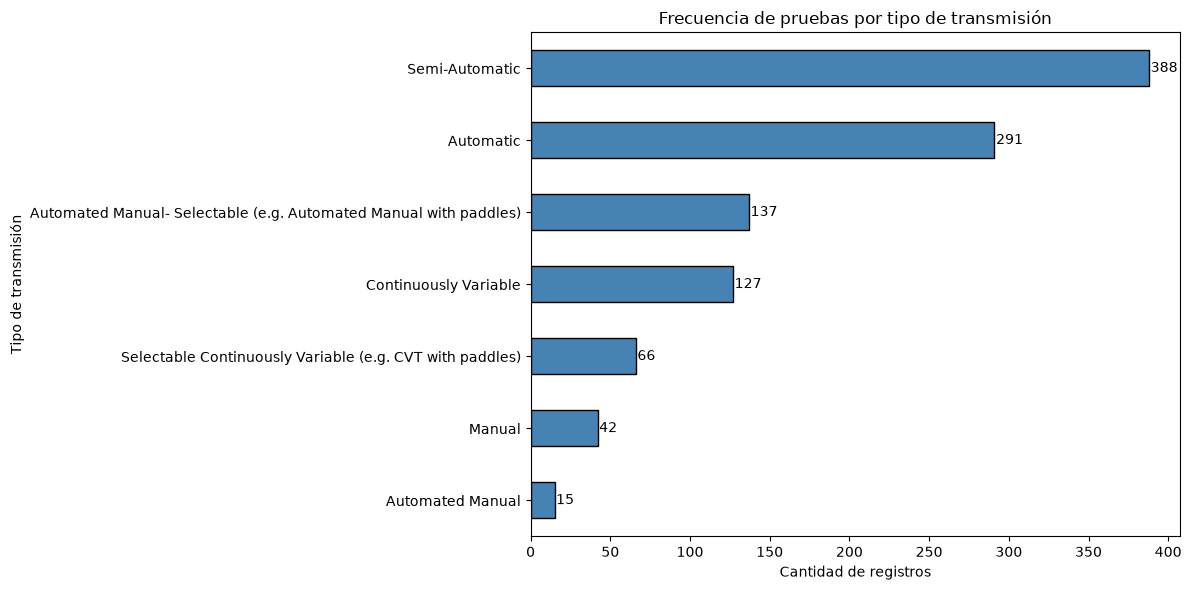

In [ ]:
frecuencia_combustibles = data["Tested Transmission Type"].value_counts().sort_values(ascending=True)

plt.figure(figsize=(12, 6))
ax = frecuencia_combustibles.plot(
    kind="barh",
    color="steelblue",
    edgecolor="black"
)

ax.set_title("Frecuencia de pruebas por tipo de transmisión")
ax.set_xlabel("Cantidad de registros")
ax.set_ylabel("Tipo de transmisión")

for i, valor in enumerate(frecuencia_combustibles):
    ax.text(valor + 1, i, str(valor), va="center")

plt.tight_layout()
plt.show()



### Podemos apreciar como automated-manual cuenta con un numero muy chico de muestras, un grupo con un N tan chico no es lo suficientemente representativa de la poblacion y por lo tanto poco confiable, de esta manera se decide excluirlo de la hipotesis.

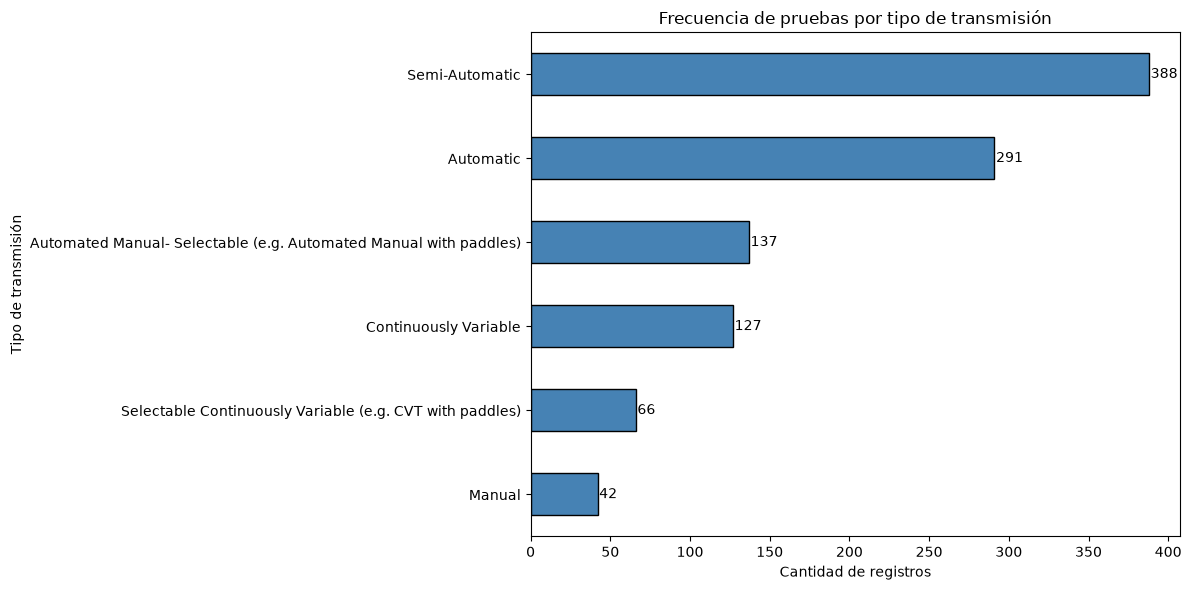

In [ ]:
data = data[data["Tested Transmission Type"] != "Automated Manual"]
frecuencia_combustibles = data["Tested Transmission Type"].value_counts().sort_values(ascending=True)

plt.figure(figsize=(12, 6))
ax = frecuencia_combustibles.plot(
    kind="barh",
    color="steelblue",
    edgecolor="black"
)

ax.set_title("Frecuencia de pruebas por tipo de transmisión")
ax.set_xlabel("Cantidad de registros")
ax.set_ylabel("Tipo de transmisión")

for i, valor in enumerate(frecuencia_combustibles):
    ax.text(valor + 1, i, str(valor), va="center")

plt.tight_layout()
plt.show()


### Ahora realicemos BoxPlots  para observar como se comporta la emision de CO2 segun el tipo de transmision

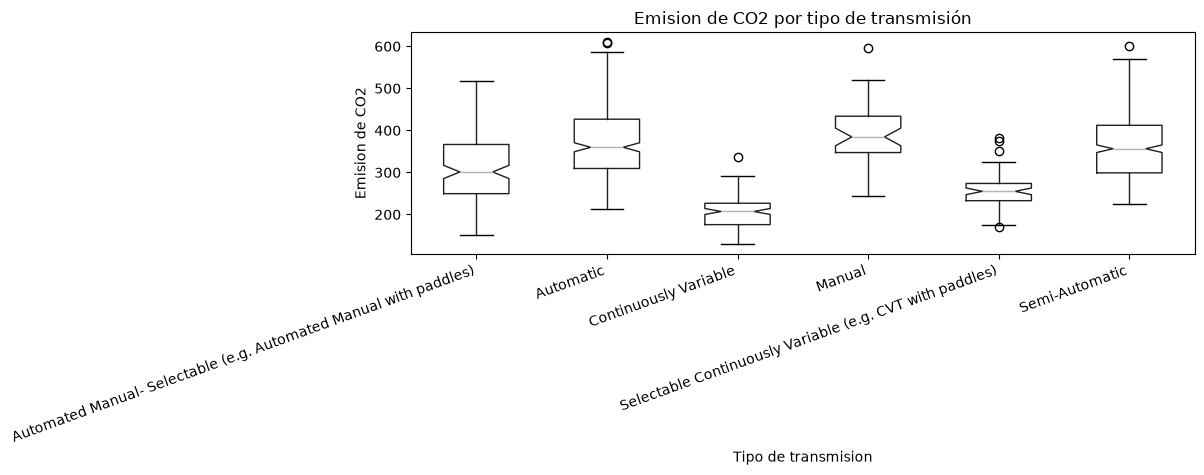

In [ ]:
ax = data.boxplot(
    column="CO2 (g/mi)",
    by="Tested Transmission Type",
    figsize=(12, 5),
    grid=False,
    notch=True
)

ax.set_title("Emision de CO2 por tipo de transmisión")
ax.set_xlabel("Tipo de transmision")
ax.set_ylabel("Emision de CO2")
plt.suptitle("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### El boxplot nos muestra que las transmisiones Continuously Variable (mediana cercana a 200 g/mi) y Selectable Continuously Variable (cercana a 250 g/mi) tienen las emisiones más bajas y la menor dispersión. Automated Manual- Selectable ocupa una posición intermedia (alrededor de 300 g/mi), mientras que Semi-Automatic, Automatic y Manual presentan los valores más altos (entre 350 y 400 g/mi aproximadamente) y una mayor variabilidad. Se observan además algunos valores atípicos en la parte superior de varias categorías.

### Las muecas no parecen coincidir entre si, salvo semi-automatic y automatic que se aproximan mucho tambien en su distribucion. En un principio todo pareceria indicar que hay diferencias significativas entre las emisiones de CO2 entre los distintos tipos de transmisiones. Pero hay que probarlo.

## PASOS:
### Dado que nos aseguramos independencia entre las variables, con mas de dos grupos nuestras opciones para llevar a cabo el test de hipotesis son Anova o Kruskall-Wallis.
### Para el primero sera necesario cumplir sus supuestos por lo que procederemos a comprobarlos
### -Normalidad (Shapiro-Wilks/QQ-plot) -> Si no se cumple se pasara directamente a Kruskall-Wallis
### -Homocedasticidad (Levene)

In [ ]:
from scipy.stats import shapiro

# Separamos los datos en dos grupos, desarrollados y en vías de desarrollo
automatic_CO2 = data[data["Tested Transmission Type"] == "Automatic"]['CO2 (g/mi)']
manual_CO2 = data[data["Tested Transmission Type"] == "Manual"]['CO2 (g/mi)']
semi_auto_CO2 = data[data["Tested Transmission Type"] == "Semi-Automatic"]['CO2 (g/mi)']
scv_wp_CO2 = data[data["Tested Transmission Type"] == "Selectable Continuously Variable (e.g. CVT with paddles)"]['CO2 (g/mi)']
auto_manual_C02 = data[data["Tested Transmission Type"] == "Automated Manual- Selectable (e.g. Automated Manual with paddles)"]['CO2 (g/mi)']
con_var_CO2 = data[data["Tested Transmission Type"] == "Continuously Variable"]['CO2 (g/mi)']
# Test de Shapiro-Wilk para países desarrollados
stat, p = shapiro(automatic_CO2)
print(f"Automatic:\t\t Estadístico = {stat:.4f}, p-valor = {p:.4g}")

stat, p = shapiro(manual_CO2)
print(f"Manual:\t\t\t Estadístico = {stat:.4f}, p-valor = {p:.4g}")

stat, p = shapiro(semi_auto_CO2)
print(f"Semi-automatic:\t\t Estadístico = {stat:.4f}, p-valor = {p:.4g}")

stat, p = shapiro(scv_wp_CO2)
print(f"Selectable CVT:\t\t Estadístico = {stat:.4f}, p-valor = {p:.4g}")

stat, p = shapiro(auto_manual_C02)
print(f"Automated Manual:\t Estadístico = {stat:.4f}, p-valor = {p:.4g}")

stat, p = shapiro(con_var_CO2)
print(f"Continuously Variable:\t Estadístico = {stat:.4f}, p-valor = {p:.4g}")


Automatic:		 Estadístico = 0.9643, p-valor = 1.333e-06
Manual:			 Estadístico = 0.9731, p-valor = 0.4158
Semi-automatic:		 Estadístico = 0.9695, p-valor = 3.03e-07
Selectable CVT:		 Estadístico = 0.9576, p-valor = 0.0242
Automated Manual:	 Estadístico = 0.9775, p-valor = 0.02287
Continuously Variable:	 Estadístico = 0.9732, p-valor = 0.01275


### Como se puede observar por los p-valores la gran mayoria no se distribuye normalmente, por lo que no se puede proceder a realizar un test de ANOVA sobre los datos y se tendra que recurrir a un Kruskall-wallis. Remarcar aun asi que los tipos de transmisiones manuales si se distribuyen normalmente respecto a su emision de CO2, tambien no es sorpresa que sea el que menor numero de muestras tenia de todas las categorias. De igual manera observemos los QQ-PLOT a continuacion.

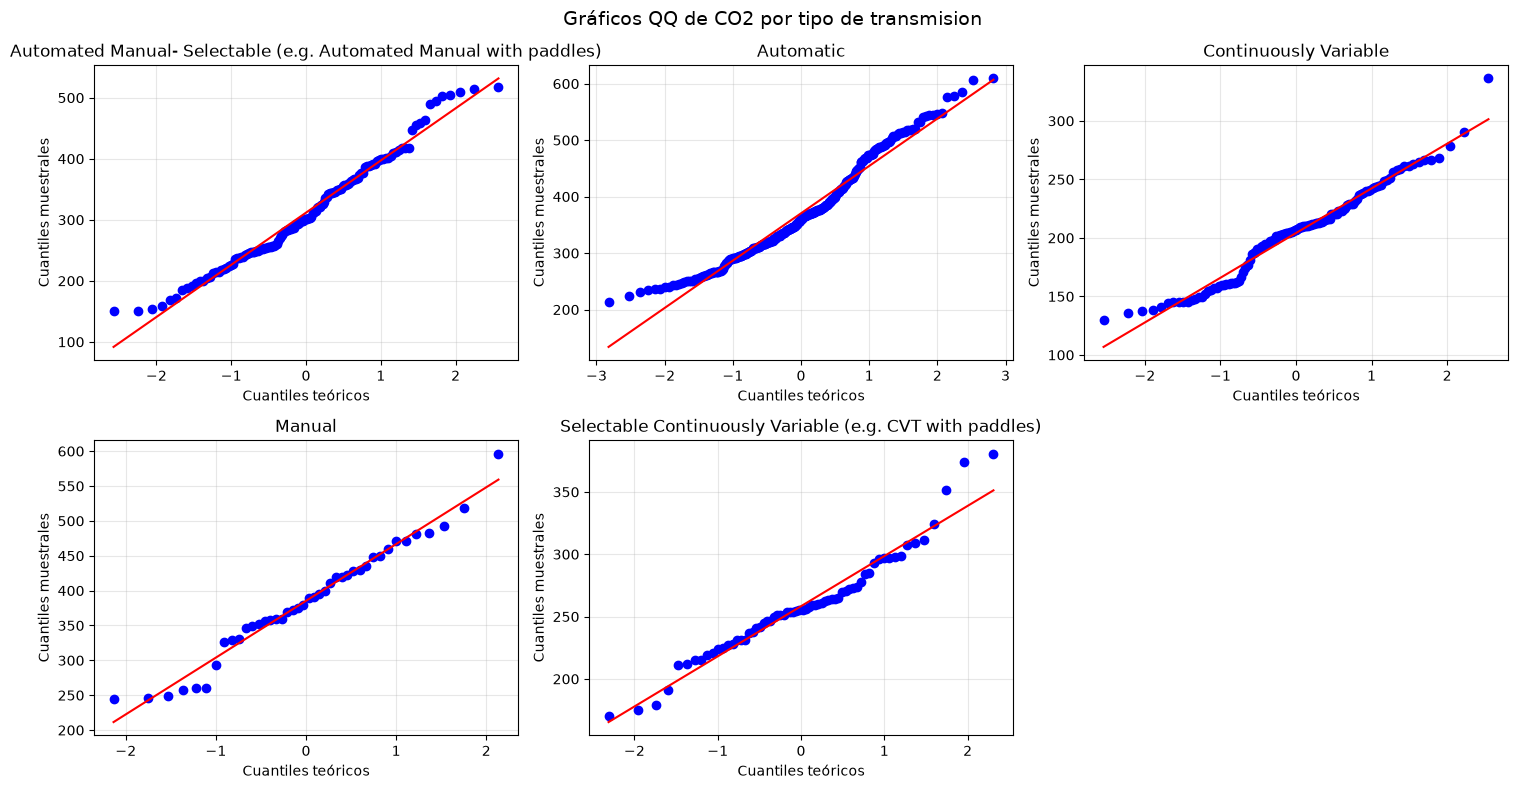

In [ ]:
from scipy import stats

import matplotlib.pyplot as plt

grupos = data.groupby("Tested Transmission Type")["CO2 (g/mi)"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax_qq, (traccion, valores) in zip(axes, grupos):
    valores = valores.dropna()
    stats.probplot(valores, dist="norm", plot=ax_qq)
    ax_qq.set_title(traccion)
    ax_qq.set_xlabel("Cuantiles teóricos")
    ax_qq.set_ylabel("Cuantiles muestrales")
    ax_qq.grid(alpha=0.3)

axes[-1].set_visible(False)
fig.suptitle("Gráficos QQ de CO2 por tipo de transmision", fontsize=14)
plt.tight_layout()
plt.show()

### Finalmente como no se cumplieron los supuestos necesarios para realizar ANOVA, procederemos a llevar a cabo Kruskall-Wallis

In [ ]:
stat, p = stats.kruskal(automatic_CO2, manual_CO2, semi_auto_CO2, scv_wp_CO2, auto_manual_C02, con_var_CO2)
alpha = 0.05  # Nivel de significancia
print(f"Test de Kruskal-Wallis para CO2 (g/mi) entre transmisiones: Estadístico={stat:.3f}, p-valor={p:.3f}")
if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en la emision de CO2 segun el tipo de transmision")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en la emision de CO2 segun el tipo de transmision")

Test de Kruskal-Wallis para CO2 (g/mi) entre transmisiones: Estadístico=404.267, p-valor=0.000
Se rechaza la hipótesis nula.
Existe una diferencia significativa en la emision de CO2 segun el tipo de transmision


# CONCLUSION:
## El p-valor < 0.05 indica que existe evidencia estadistica suficiente para rechazar la hipotesis nula (H0). Esto puede afirmar la hipotesis alternativa(H1). De esta manera se puede afirmar, que efectivamente, existen diferencias en la emision de CO2 entre los vehiculos a combustion en ciclos urbanos.

---

# HIPOTESIS DE LA CATEDRA 2

## Hipótesis — En vehículos de combustión, la economía de combustible difiere según el sistema de tracción. 


In [1140]:
# ============ CONFIGURACIÓN Y CARGA ============
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from itertools import combinations

df = pd.read_excel("25-testcar-2026-01-21.xlsx")
data = df.copy()

### Para empezar, al igual que ocurrio con la hipotesis bivariada propuesta por nuestro grupo, se debe hacer la limpieza de los siguientes aspectos del DataFrame:
#### - Eliminacion de vehiculos electricos e hidridos que utilicen Hidrogeno 5 (Ademas aqui se decidio eliminar todos los hibridos, observar mas adelante) 
#### - Eliminacion de valores nulos, 0's y outliers que inquen potenciales errores de muestreo o tipeo.
#### - Modificacion del DataSet para cumplir independencia


## Empecemos limpiando electricos e hibridos que utilizan Hydrogeno 5

In [1141]:
fuel_pairs = (
    df[["Test Fuel Type Cd", "Test Fuel Type Description"]]
    .drop_duplicates()
    .sort_values(["Test Fuel Type Cd", "Test Fuel Type Description"])
)
fuel_pairs

,Test Fuel Type Cd,Test Fuel Type Description
1313,19,Federal Cert Diesel 7-15 PPM Sulfur
633,26,Cold CO Regular (Tier 2)
106,27,Cold CO Premium (Tier 2)
2461,28,Cold CO E10 Regular Gasoline (Tier 3)
1052,38,E85 (85% Ethanol 15% EPA Unleaded Gasoline)
2465,46,CARB LEV3 E10 Regular Gasoline
3021,47,CARB LEV3 E10 Premium Gasoline
2462,48,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)
1845,50,Hydrogen 5
0,61,Tier 2 Cert Gasoline


- **62 – Electricity**: vehículos eléctricos → no son de combustión, **se eliminan**.
- **50 – Hydrogen 5**: celda de combustible (Honda CR-V e:FCEV) → no quema combustible en un motor de combustión, **se elimina**.
- El resto (gasolina Tier 2 / Tier 3 / CARB LEV3, *Cold CO*, E85 y diésel) son combustibles de ensayo de motores de combustión, **se conservan**. Los "Cold CO ..." son el mismo tipo de combustible utilizado en el ensayo de arranque en frío.




In [1142]:
data = data[(data["Test Fuel Type Cd"] != 50) & (data["Test Fuel Type Cd"] != 62)]

In [1143]:

valores_unicos = data[["Test Fuel Type Cd", "Test Fuel Type Description"]].drop_duplicates()

valores_unicos = valores_unicos.sort_values(by="Test Fuel Type Cd")

valores_unicos

,Test Fuel Type Cd,Test Fuel Type Description
1313,19,Federal Cert Diesel 7-15 PPM Sulfur
633,26,Cold CO Regular (Tier 2)
106,27,Cold CO Premium (Tier 2)
2461,28,Cold CO E10 Regular Gasoline (Tier 3)
1052,38,E85 (85% Ethanol 15% EPA Unleaded Gasoline)
2465,46,CARB LEV3 E10 Regular Gasoline
3021,47,CARB LEV3 E10 Premium Gasoline
2462,48,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)
0,61,Tier 2 Cert Gasoline


## Busqueda de nulos, ceros y outleirs en `RND_ADJ_FE`

In [1144]:
data["RND_ADJ_FE"].describe()

count     3493.000000
mean        58.291125
std        488.892989
min          8.000000
25%         23.700000
50%         31.800000
75%         40.500000
max      10000.000000
Name: RND_ADJ_FE, dtype: float64

### La economia de combustible presenta resultados muy extraños en su describe. Una media muy por encima de la mediana (asimetria con cola a derecha), un desvio estandar sumamente superior a la media, y por sobre todas las cosas un valor maximo de 10.000 que cual apunta a ser el principal responsable de todo lo anterior nombrado. Por lo que habra que investigar este outlier y la potencial presencia de otros en la variable

In [1145]:
null_fe_values = data['RND_ADJ_FE'].isna().sum()
cero_fe_values = (data['RND_ADJ_FE'] == 0).sum()
print(null_fe_values)
print(cero_fe_values)
nanFeRows = data["RND_ADJ_FE"].isna()
filas_nulas = data[nanFeRows]
filas_nulas[["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Test Fuel Type Description", "Test Procedure Description", "RND_ADJ_FE"]]

130
0


,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,Test Fuel Type Description,Test Procedure Description,RND_ADJ_FE
107,BMX,CP43825,2,Tier 2 Cert Gasoline,Charge Depleting UDDS,NaN
108,BMX,CP43825,2,Tier 2 Cert Gasoline,Charge Depleting Highway,NaN
120,BMX,CJ80117,0,Tier 2 Cert Gasoline,Charge Depleting UDDS,NaN
121,BMX,CJ80117,0,Tier 2 Cert Gasoline,Charge Depleting Highway,NaN
358,BMX,CN43567,3,Tier 2 Cert Gasoline,Charge Depleting UDDS,NaN
...,...,...,...,...,...,...
4241,VVX,202212,1,Tier 2 Cert Gasoline,Charge Depleting Highway,NaN
4251,VVX,202211,2,Tier 2 Cert Gasoline,Charge Depleting Highway,NaN
4254,VVX,202211,2,Tier 2 Cert Gasoline,Charge Depleting UDDS,NaN
4259,VVX,202308,0,Tier 2 Cert Gasoline,Charge Depleting Highway,NaN


### Nos encontramos con varios valores nulos presentes en la economia de combustible, investiguemoslo:  
| Grupo | Combustible | Procedimiento de ensayo | Filas | Valor | Qué pasa |
|---|---|---|---:|---|---|
| PHEV en modo Charge Depleting (CD) | Tier 2 Cert Gasoline | Charge Depleting UDDS (65) y Charge Depleting Highway (65) | 130 | Nulo | En modo CD (Charge Depleting) el motor no quema gasolina, por lo que no hay consumo de combustible que reportar. CO2, THC, CO y NOx también están 100 % vacíos. |

In [1146]:
data = data.drop(data[data["RND_ADJ_FE"] == 0].index)
data = data.drop(data[data["RND_ADJ_FE"].isna()].index)
null_fe_values = data['RND_ADJ_FE'].isna().sum()
cero_fe_values = (data['RND_ADJ_FE'] == 0).sum()
print(null_fe_values)
print(cero_fe_values)

0
0


## Ahora tratemos los Outliers presentes en `RND_ADJ_FE`

#### Primero realizamos un BoxPlot

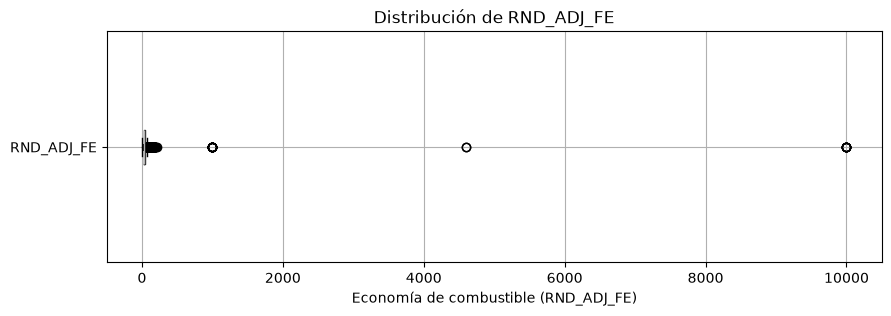

In [1147]:
df.boxplot(column="RND_ADJ_FE", vert=False, figsize=(10, 3))

plt.title("Distribución de RND_ADJ_FE")
plt.xlabel("Economía de combustible (RND_ADJ_FE)")
plt.show()

### Como se sospechaba, hay un salto abismal entre el último valor creíble (82,8 MPG) y las siguientes 8 filas con un valor de 9999,9999999 (≈ 10.000 en la tabla; claramente un valor no plausible para MPG e implicaria "dato no disponible") y 2 filas con 4595,3 y 4599,1 MPG. Ningún auto rinde así (4.595 MPG equivaldrían a casi 2.000 km por litro), por lo que se tratan como errores de registro y se eliminan.


In [1148]:
data[ (data["RND_ADJ_FE"] > 4000) & (data["RND_ADJ_FE"] <= 10000) ]


,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,...,Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Cd,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc
2461,2025,Lotus,LTX,Lotus,Emira,EDV-25-EVSA6,0,3.500,SLTXV03.5JHB,Car,...,15.804,0.15738,0.024292,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2462,2025,Lotus,LTX,Lotus,Emira,EDV-25-EVSA6,0,3.500,SLTXV03.5JHB,Car,...,10.858,-0.00289,0.022824,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2463,2025,Lotus,LTX,Lotus,Emira,EDV-25-EVSM6,0,3.500,SLTXV03.5JHB,Car,...,19.963,0.24494,0.018929,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2464,2025,Lotus,LTX,Lotus,Emira,EDV-25-EVSM6,0,3.500,SLTXV03.5JHB,Car,...,19.963,0.24494,0.018929,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2465,2025,Lotus,LTX,Lotus,Emira,EDV-25-EVSM6,0,3.500,SLTXV03.5JHB,Car,...,19.963,0.24494,0.018929,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2466,2025,Lotus,LTX,Lotus,Emira,EDV-25-EVSM6,0,3.500,SLTXV03.5JHB,Car,...,23.268,0.13640,0.022050,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3021,2025,Pagani S.p.A.,PGN,Pagani SpA,Utopia,ZA9U11EBYYSF76004,0,6.000,RPGNV06.0PHT,Car,...,4.970,-0.13680,0.022950,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3022,2025,Pagani S.p.A.,PGN,Pagani SpA,Utopia,ZA9U11EBYYSF76004,0,6.000,RPGNV06.0PHT,Car,...,4.970,-0.13680,0.022950,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3460,2025,Toyota,TYX,LEXUS,RC F,20-UC1A,0,4.969,LTYXV05.0M5A,Car,...,23.296,-0.15818,0.022392,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3466,2025,Toyota,TYX,LEXUS,RC F,20-UC1A,0,4.969,LTYXV05.0M5A,Car,...,23.296,-0.15818,0.022392,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging


count    3483.000000
mean       32.849986
std        11.823119
min         8.000000
25%        23.700000
50%        31.800000
75%        40.400000
max        82.800000
Name: RND_ADJ_FE, dtype: float64


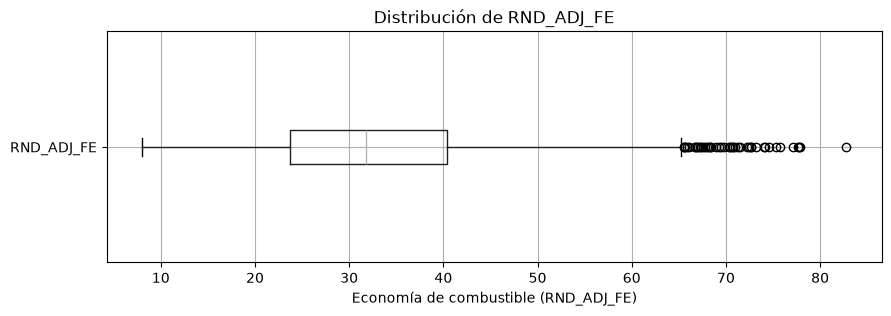

In [1149]:
data = data[data["RND_ADJ_FE"] <= 4000]

print(data["RND_ADJ_FE"].describe())

data.boxplot(column="RND_ADJ_FE", vert=False, figsize=(10, 3))

plt.title("Distribución de RND_ADJ_FE")
plt.xlabel("Economía de combustible (RND_ADJ_FE)")
plt.show()

### Tras la limpieza el rango es 8,0 – 82,8 MPG, coherente con autos reales. Aun asi, analisemos esos outliers utilizando la regla del rango intercuartilico (1.5* IQR) de Tukey, estableciendo un rango de confianza.



In [1150]:
cuantil_1 = data["RND_ADJ_FE"].quantile(0.25)
cuantil_3 = data["RND_ADJ_FE"].quantile(0.75)

iqr = cuantil_3 - cuantil_1

limite_superior = cuantil_3 + 1.5 * iqr
print(limite_superior)
outliers_restantes = data[ (data["RND_ADJ_FE"] >= limite_superior)]
outliers_restantes[["Veh Mfr Code", "Represented Test Veh Make", "Represented Test Veh Model", "RND_ADJ_FE"]].sort_values(by=["Represented Test Veh Make", "Represented Test Veh Model", "RND_ADJ_FE"], ascending=False)

65.44999999999999


,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,RND_ADJ_FE
3747,TYX,TOYOTA,PRIUS XLE/LTD,75.7
3749,TYX,TOYOTA,PRIUS XLE/LTD,73.2
3741,TYX,TOYOTA,PRIUS PRIME SE,77.7
3743,TYX,TOYOTA,PRIUS PRIME SE,72.7
3737,TYX,TOYOTA,PRIUS PRIME,70.3
3734,TYX,TOYOTA,PRIUS PRIME,66.1
3731,TYX,TOYOTA,PRIUS AWD XLE/LTD,71.0
3727,TYX,TOYOTA,PRIUS AWD XLE/LTD,69.3
3724,TYX,TOYOTA,PRIUS AWD,77.9
3722,TYX,TOYOTA,PRIUS AWD,74.6


### Investigando sobre todos aquellos vehiculos que superan el limite superior planteado hayamos dos grupos: 

#### - Grupo 1 (híbridos): Toyota Camry HEV AWD LE, Camry HEV FF LE, Corolla Cross Hybrid AWD, Corolla Hybrid, Corolla Hybrid AWD, Prius, Prius AWD, Prius AWD XLE/LTD, Prius Prime, Prius Prime SE y Prius XLE/LTD; Lexus UX 300h; Hyundai Elantra Hybrid, Elantra Hybrid Blue y Sonata Hybrid; Kia Niro Hybrid y Niro PHEV.

#### - Grupo 2 (combustión o desconocidos): Honda Civic 4Dr y Civic 5Dr, que figuran como autos a combustión, y Honda Accord y Accord Sport/Touring, que tienen versiones hibridas en el mercado, pero se desconoce si es el caso porque el nombre no lo aclara.

### Se tomo la decision de eliminar todos aquellos autos en esta lista, menos las correspondientes al Honda Civic 4Dr y Civic 5Dr, los cuales se determino que no eran hibridos. Todo esto con el objetivo de poder cumplir con la hipotesis y poder tener resultados mas representativos acordes a los autos a combustion. Si queremos analizar el MPG de los autos a combustión, los híbridos distorsionan los resultados porque funcionan de una manera distinta. Rinden bastante más millas por galón gracias al motor eléctrico, por lo que es normal que obtengan un MPG mayor, y eso no tiene que ver con cómo se comporta un motor a nafta común.

In [1151]:
modelos_civic = ["CIVIC 4Dr", "CIVIC 5Dr"]

civic = outliers_restantes[
    outliers_restantes["Represented Test Veh Model"].str.casefold().isin(
        [modelo.casefold() for modelo in modelos_civic]
    )
]

# Restaurar los Civic si ya habían sido eliminados de data
faltantes = civic.loc[~civic.index.isin(data.index)]
data = pd.concat([data, faltantes])

# Eliminar los demás outliers
indices_eliminar = outliers_restantes.index.difference(civic.index)
data = data.drop(index=indices_eliminar, errors="ignore")

In [1152]:
data["RND_ADJ_FE"].describe()
data_len = len(data)
print(data_len)


3446


### Finalmente este resumen si luce mucho mas prolijo de lo que se habia visto anteriormente, con una media y mediana mas parejas, un desvio estandar adecuado al resto de valores, y aunque cuenta aun con los outliers que mantuvimos, es acorde a lo que se quiere testear.

### Para terminar con RND_ADJ_FE se abordo la posible incidencia que podria tener el Test Category, o ciclos, realizado sobre un vehiculo en cuanto su fuel economy. ¿Por que? Se investigo que manejar en ciudad obliga al motor a trabajar de forma poco eficiente. En un ciclo urbano hay muchas frenadas, arranques y paradas, y cada vez que el auto tiene que volver a acelerar desde cero, el motor gasta mucho combustible para vencer la inercia. Además, en los semáforos o en el tráfico el motor sigue encendido en ralentí, consumiendo nafta sin avanzar ni un metro.

### Lo mismo ocurriria con los ciclos de SCO3 (de este no quedan en el DataSet limpio) o US06, este ultimo por sobre todo, dado que presenta un tipo de test de conducción agresiva y a alta velocidad. Tiene aceleraciones fuertes y velocidades que llegan a unas 80 mph (cerca de 130 km/h). Como el motor trabaja con más carga, el MPG suele ser menor que en el ciclo de autopista normal

### En cambio, en un ciclo de autopista el auto va a velocidad más o menos constante. El motor trabaja en un régimen estable y eficiente, sin tener que acelerar y frenar todo el tiempo, y por eso recorre más millas por galón.

### Para abordar esto, se decidio que se va a testear la hipotesis de economia de combustible segun traccion por cada tipo de Test Category


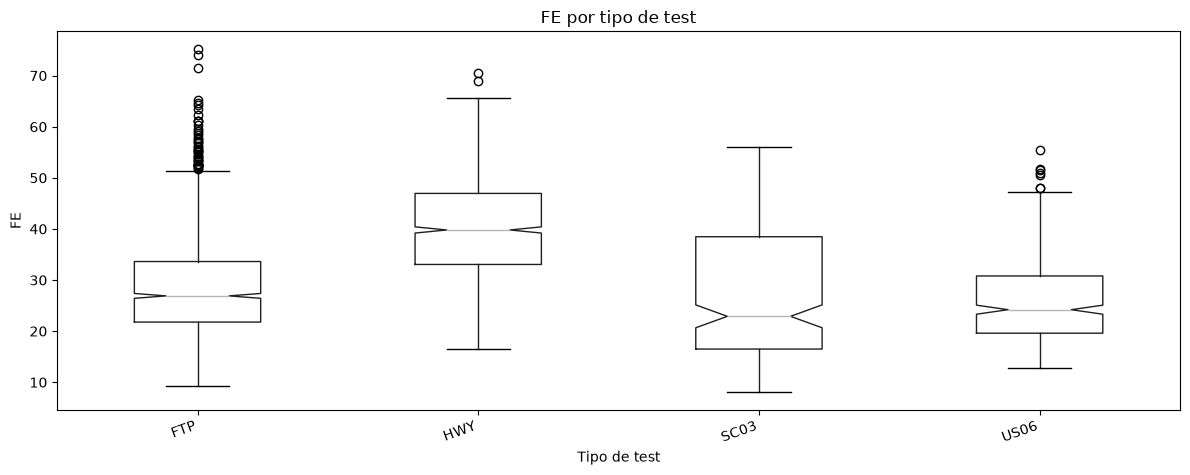

In [1153]:

ax = data.boxplot(
    column="RND_ADJ_FE",
    by="Test Category",
    figsize=(12, 5),
    grid=False,
    notch=True
)

ax.set_title("FE por tipo de test")
ax.set_xlabel("Tipo de test")
ax.set_ylabel("FE")
plt.suptitle("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Como se adelanto, HWY cuenta con los valores más altos, con una mediana cercana a 40, porque a velocidad constante el motor trabaja de forma más eficiente. Las otras tres pruebas (urbano, aire acondicionado y conducción agresiva) tienen medianas parecidas y más bajas, entre 23 y 27, porque en todas el motor se exige más, ya sea por las frenadas y arranques, por el aire acondicionado o por las aceleraciones fuertes.

#### Antes de crear cada subgrupo de test, comprobemos que ocurre con Drive System Description (Traccion)

## Ahora observemos que ocurre con la columna de tipo de traccion


In [1154]:
unique_traction = data["Drive System Description"].unique()
pd.DataFrame(unique_traction, columns=["Drive System Description"])

,Drive System Description
0,"2-Wheel Drive, Rear"
1,4-Wheel Drive
2,All Wheel Drive
3,"2-Wheel Drive, Front"
4,Part-time 4-Wheel Drive


**Descripción de cada tipo de tracción**

- **2-Wheel Drive, Front (FWD – delantera):** la potencia va solo a las ruedas delanteras. Es el sistema más común en autos de uso diario; buena eficiencia porque es liviano y mecánicamente simple.
- **2-Wheel Drive, Rear (RWD – trasera):** la potencia va solo a las ruedas traseras. Estándar en deportivos y camionetas de trabajo; mejor reparto de peso y capacidad de carga/remolque.
- **All Wheel Drive (AWD – total):** envía potencia a las cuatro ruedas de forma continua y automática; ideal en pavimento mojado, hielo o nieve.
- **4-Wheel Drive (4WD – 4x4):** tracción a las cuatro ruedas, mecánica, para clima severo o uso todoterreno; componentes más robustos y caja de transferencia con reductora.
- **Part-time 4-Wheel Drive (4x4 parcial / conectable):** funciona normalmente con tracción a dos ruedas y el conductor activa manualmente las cuatro ruedas cuando hace falta.

### Ademas, no hay presencia de valores NaN:

In [1155]:
null_DSD_values = data["Drive System Description"].isna().sum()
print(null_DSD_values)

0


### Ahora si, separemos los grupos de test por categoria y hagamos el tratamiento para evitar dependencia.

In [1156]:
data_HWY = data.loc[data["Test Category"] == "HWY"].copy()
data_FTP = data.loc[data["Test Category"] == "FTP"].copy()
data_US06 = data.loc[data["Test Category"] == "US06"].copy()

print(f"HWY: {len(data_HWY)} filas")
print(f"FTP: {len(data_FTP)} filas")
print(f"US06: {len(data_US06)} filas")

HWY: 1295 filas
FTP: 1520 filas
US06: 393 filas


## Limpieza y chequeo de independencia

#### Al igual que ocurrio con la hipotesis Bivariada propuesta por nuestro grupo nos encontramos con el casos de varias filas correspondientes a tests realizados sobre un mismo vehiculo con una misma configuracion de ensayo o test. De esta manera, para poder garantizar independencia entre las observaciones se decidio agrupar por Veh Mfr Code, Test Vehicle ID y Test Veh Configuration, colapsando los valores de emision de CO2, en caso de haber varios, a un unico por vehiculo utilizando la mediana. (Mas arriba en la bivariada propuesta por el grupo se suma la explicacion del porque de la repeticion) En este caso se hizo por cada uno de los subgrupos creados.

In [1157]:
mascara = data_HWY.duplicated(subset=["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Drive System Description"], keep=False)

filas_repetidas = data_HWY[mascara]
filas_repetidas[["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Drive System Description", "RND_ADJ_FE", "Test Fuel Type Description", "Aftertreatment Device Cd"]]


,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,Drive System Description,RND_ADJ_FE,Test Fuel Type Description,Aftertreatment Device Cd
14,BMX,8D89453,0,"2-Wheel Drive, Rear",51.6,Tier 2 Cert Gasoline,OT
15,BMX,8D89453,0,"2-Wheel Drive, Rear",51.6,Tier 2 Cert Gasoline,TWC
18,BMX,8D89453,1,"2-Wheel Drive, Rear",47.2,Tier 2 Cert Gasoline,TWC
19,BMX,8D89453,1,"2-Wheel Drive, Rear",47.2,Tier 2 Cert Gasoline,OT
22,BMX,8D89454,0,All Wheel Drive,49.9,Tier 2 Cert Gasoline,TWC
...,...,...,...,...,...,...,...
4134,VGA,VW416150015,0,All Wheel Drive,35.0,Tier 2 Cert Gasoline,TWC
4181,VGA,VW371050045,1,"2-Wheel Drive, Front",57.9,Tier 2 Cert Gasoline,TWC
4182,VGA,VW371050045,1,"2-Wheel Drive, Front",58.2,Tier 2 Cert Gasoline,TWC
4187,VGA,VW316550199,0,All Wheel Drive,46.7,Tier 2 Cert Gasoline,TWC


In [1158]:
mascara = data_FTP.duplicated(subset=["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Drive System Description"], keep=False)

filas_repetidas = data_FTP[mascara]
filas_repetidas[["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Drive System Description", "RND_ADJ_FE", "Test Fuel Type Description", "Aftertreatment Device Cd"]]


,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,Drive System Description,RND_ADJ_FE,Test Fuel Type Description,Aftertreatment Device Cd
12,BMX,8D89453,0,"2-Wheel Drive, Rear",36.2,Tier 2 Cert Gasoline,OT
13,BMX,8D89453,0,"2-Wheel Drive, Rear",36.2,Tier 2 Cert Gasoline,TWC
16,BMX,8D89453,1,"2-Wheel Drive, Rear",33.7,Tier 2 Cert Gasoline,TWC
17,BMX,8D89453,1,"2-Wheel Drive, Rear",33.7,Tier 2 Cert Gasoline,OT
20,BMX,8D89454,0,All Wheel Drive,34.3,Tier 2 Cert Gasoline,TWC
...,...,...,...,...,...,...,...
4153,VGA,VW38004-0068,0,All Wheel Drive,28.0,Tier 2 Cert Gasoline,TWC
4186,VGA,VW316550199,0,All Wheel Drive,32.5,Tier 2 Cert Gasoline,TWC
4188,VGA,VW316550199,0,All Wheel Drive,32.4,Tier 2 Cert Gasoline,TWC
4249,VVX,202520,0,"2-Wheel Drive, Front",29.7,Tier 2 Cert Gasoline,TWC


In [1159]:
mascara = data_US06.duplicated(subset=["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Drive System Description"], keep=False)

filas_repetidas = data_US06[mascara]
filas_repetidas[["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Drive System Description", "RND_ADJ_FE", "Test Fuel Type Description", "Aftertreatment Device Cd"]]


,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,Drive System Description,RND_ADJ_FE,Test Fuel Type Description,Aftertreatment Device Cd
706,CRX,L4JLJ7094,1,"2-Wheel Drive, Rear",21.3,Tier 2 Cert Gasoline,TWC
708,CRX,L4JLJ7094,1,"2-Wheel Drive, Rear",20.8,Tier 2 Cert Gasoline,TWC
792,FMX,MLA60016,0,"2-Wheel Drive, Rear",19.2,Tier 2 Cert Gasoline,TWC
794,FMX,MLA60016,0,"2-Wheel Drive, Rear",18.5,Tier 2 Cert Gasoline,TWC
798,FMX,MLA60032,0,"2-Wheel Drive, Rear",16.7,Tier 2 Cert Gasoline,TWC
...,...,...,...,...,...,...,...
3773,TYX,19-AA2H,1,"2-Wheel Drive, Front",36.8,Tier 2 Cert Gasoline,TWC
3872,TYX,25-AS1H,1,"2-Wheel Drive, Front",36.1,Tier 2 Cert Gasoline,TWC
3873,TYX,25-AS1H,1,"2-Wheel Drive, Front",35.9,Tier 2 Cert Gasoline,TWC
3922,VGA,RA7G-A4-447,0,All Wheel Drive,28.4,Tier 2 Cert Gasoline,TWC


In [1160]:
data_HWY = data_HWY.groupby(["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Drive System Description"])["RND_ADJ_FE"].median().reset_index()
data_FTP = data_FTP.groupby(["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Drive System Description"])["RND_ADJ_FE"].median().reset_index()
data_US06 = data_US06.groupby(["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #", "Drive System Description"])["RND_ADJ_FE"].median().reset_index()
print(f"HWY: {len(data_HWY)} filas")
print(f"FTP: {len(data_FTP)} filas")
print(f"US06: {len(data_US06)} filas")

HWY: 1060 filas
FTP: 1084 filas
US06: 316 filas


## Ahora si, estamos listos para llevar a cabo el test de hipotesis

### Analicemos primero la frecuencia de tipo de traccion por cada subgrupo creado

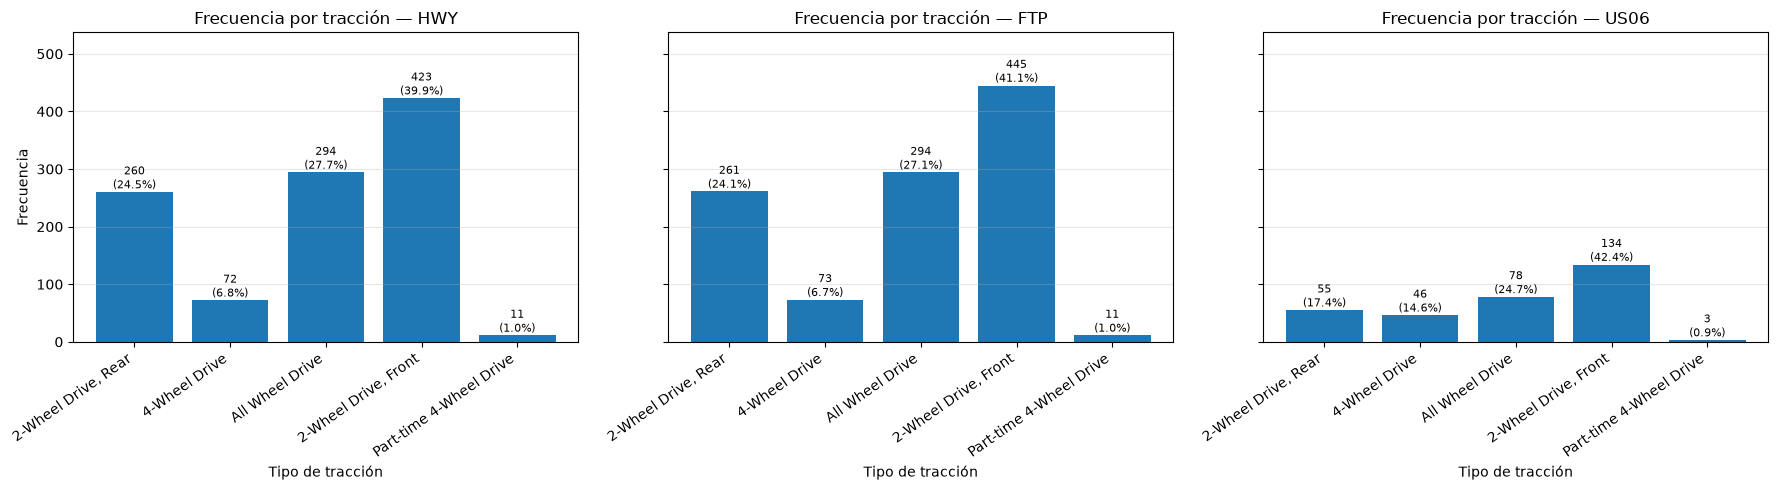

In [1161]:
datasets = {
    "HWY": data_HWY,
    "FTP": data_FTP,
    "US06": data_US06
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, (categoria, subdata) in zip(axes, datasets.items()):
    frecuencias = (
        subdata["Drive System Description"]
        .value_counts()
        .reindex(unique_traction, fill_value=0)
    )
    
    total = frecuencias.sum()     
    barras = ax.bar(range(len(frecuencias)), frecuencias.values)
    
    ax.set_xticks(range(len(frecuencias)))
    ax.set_xticklabels(frecuencias.index, rotation=35, ha="right")
    ax.set_title(f"Frecuencia por tracción — {categoria}")
    ax.set_xlabel("Tipo de tracción")
    
    if ax == axes[0]:
        ax.set_ylabel("Frecuencia")
        
    ax.grid(axis="y", alpha=0.3)
    
    # Iteramos sobre cada barra para agregar el texto
    for barra in barras:
        valor_absoluto = int(barra.get_height())
        porcentaje = (valor_absoluto / total * 100) if total > 0 else 0
        
        # Etiqueta con formato: Absoluto \n (Porcentaje%)
        etiqueta = f"{valor_absoluto}\n({porcentaje:.1f}%)"
        
        ax.text(
            barra.get_x() + barra.get_width() / 2, # Centro de la barra en X
            valor_absoluto,                        # Tope de la barra en Y
            etiqueta,                              # Texto a mostrar
            ha='center',                           # Centrado horizontal
            va='bottom',                           # Por encima de la barra
            fontsize=8                             # Tamaño de letra un poco más chico para que entre
        )

# Aumentamos un poco el espacio superior para que los textos no se corten
plt.ylim(top=axes[0].get_ylim()[1] * 1.15) 
plt.tight_layout()
plt.show()

### Se puede apreciar como en general todos los tipos de traccion cuentan con N lo suficientemente grandes como para poder ser suficientemente rerpesentativos y confiables, no siendo el caso de Part-Time 3-Wheel Drive el cual en los 3 grupos cuenta con un N muy chiquitito, poco representativo y poco confiable, por lo que se decide excluirlo del test de hipotesis.

In [1162]:
data_HWY = data_HWY[data_HWY["Drive System Description"] != "Part-time 4-Wheel Drive"]
data_FTP = data_FTP[data_FTP["Drive System Description"] != "Part-time 4-Wheel Drive"]
data_US06 = data_US06[data_US06["Drive System Description"] != "Part-time 4-Wheel Drive"]

### Ahora realicemos BoxPlots en cada grupo por tipo de traccion para observar como se comporta la economia de combustible

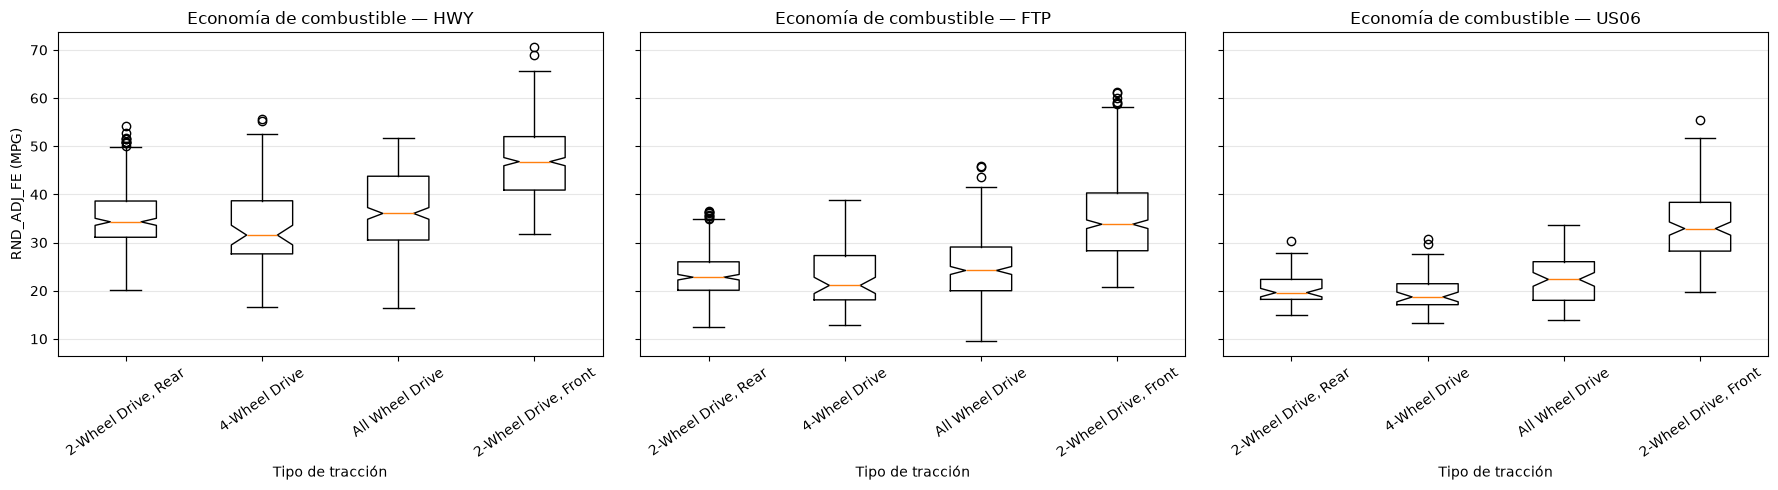

In [1163]:
# Boxplot de RND_ADJ_FE por tipo de tracción en cada categoría de ensayo
grupos_test = {
    "HWY": data_HWY,
    "FTP": data_FTP,
    "US06": data_US06
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, (categoria, subdata) in zip(axes, grupos_test.items()):
    tracciones = [
        t for t in unique_traction
        if (subdata["Drive System Description"] == t).any()
    ]
    datos = [
        subdata.loc[
            subdata["Drive System Description"] == t, "RND_ADJ_FE"
        ].dropna().to_numpy()
        for t in tracciones
    ]

    # Aquí agregamos notch=True para que tengan formato notched
    ax.boxplot(datos, tick_labels=tracciones, notch=True)
    
    ax.set_title(f"Economía de combustible — {categoria}")
    ax.set_xlabel("Tipo de tracción")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("RND_ADJ_FE (MPG)")
plt.tight_layout()
plt.show()

### Los boxplots nos muestran que la tracción delantera (2-Wheel Drive, Front) es la que tiene la mejor eficiencia de combustible en las tres pruebas, con una mediana muy por encima del resto de tipos de tracción. Su mediana ronda los 47 en autopista (HWY), 34 en ciudad (FTP) y 33 en conducción agresiva (US06). Las demás (2-Wheel Drive, Rear (tracción trasera), 4-Wheel Drive (tracción 4x4) y All Wheel Drive (tracción integral)) quedan bastante parecidas entre sí: unos 32 a 36 en autopista, 21 a 24 en ciudad y 19 a 22 en conducción agresiva, con All Wheel Drive (tracción integral) apenas por encima de 2-Wheel Drive, Rear (tracción trasera) y 4-Wheel Drive (tracción 4x4). Las muecas parecen coincidir entre pares por tipo de ciclo realizado, como por ejemplo entre All Wheel Drive y 2-Wheel Drive, Front en FTP. 

### Todo parece indicar que hay diferencias significativas entre la economia de combustible segun el tipo combustible. Pero hay que probarlo.

## PASOS:
### Dado que nos aseguramos independencia entre las variables, con mas de dos grupos nuestras opciones para llevar a cabo el test de hipotesis son Anova o Kruskall-Wallis.
### Para el primero sera necesario cumplir sus supuestos por lo que procederemos a comprobarlos
### -Normalidad (Shapiro-Wilks/QQ-plot) -> Si no se cumple se pasara directamente a Kruskall-Wallis
### -Homocedasticidad (Levene)

In [1164]:
from scipy.stats import shapiro

FE = "RND_ADJ_FE"
TRACCION = "Drive System Description"
print("TEST DE SHAPIRO PARA TEST CATEGORY:HWY")
print("                               ")
# Test de Shapiro-Wilk de RND_ADJ_FE para cada tipo de tracción
for traccion, valores in data_HWY.groupby(TRACCION)[FE]:
    stat, p = shapiro(valores)
    print(f"{traccion:<28} n = {len(valores):<5} Estadístico = {stat:.4f}, p-valor = {p:.4g}")
print("=========================================")   
print("TEST DE SHAPIRO PARA TEST CATEGORY:FTP")
print("                               ")
for traccion, valores in data_FTP.groupby(TRACCION)[FE]:
    stat, p = shapiro(valores)
    print(f"{traccion:<28} n = {len(valores):<5} Estadístico = {stat:.4f}, p-valor = {p:.4g}")
print("=========================================")   
print("TEST DE SHAPIRO PARA TEST CATEGORY:US06")
print("                               ")
for traccion, valores in data_US06.groupby(TRACCION)[FE]:
    stat, p = shapiro(valores)
    print(f"{traccion:<28} n = {len(valores):<5} Estadístico = {stat:.4f}, p-valor = {p:.4g}")

TEST DE SHAPIRO PARA TEST CATEGORY:HWY
                               
2-Wheel Drive, Front         n = 423   Estadístico = 0.9860, p-valor = 0.0004282
2-Wheel Drive, Rear          n = 260   Estadístico = 0.9603, p-valor = 1.426e-06
4-Wheel Drive                n = 72    Estadístico = 0.9519, p-valor = 0.007899
All Wheel Drive              n = 294   Estadístico = 0.9692, p-valor = 6.139e-06
TEST DE SHAPIRO PARA TEST CATEGORY:FTP
                               
2-Wheel Drive, Front         n = 445   Estadístico = 0.9483, p-valor = 2.407e-11
2-Wheel Drive, Rear          n = 261   Estadístico = 0.9647, p-valor = 5.072e-06
4-Wheel Drive                n = 73    Estadístico = 0.9403, p-valor = 0.001806
All Wheel Drive              n = 294   Estadístico = 0.9876, p-valor = 0.0126
TEST DE SHAPIRO PARA TEST CATEGORY:US06
                               
2-Wheel Drive, Front         n = 134   Estadístico = 0.9591, p-valor = 0.0004885
2-Wheel Drive, Rear          n = 55    Estadístico = 0.9319, p

### Como se puede observar por los p-valores la gran mayoria no se distribuye normalmente, por lo que no se puede proceder a realizar un test de ANOVA sobre los datos y se tendra que recurrir a un Kruskall-wallis. Remarcar aun asi que los tipos de All Wheel Drive bajo ciclo US06 si se distribuyen normalmente respecto a economia de combustible. De igual manera observemos los QQ-PLOT a continuacion.

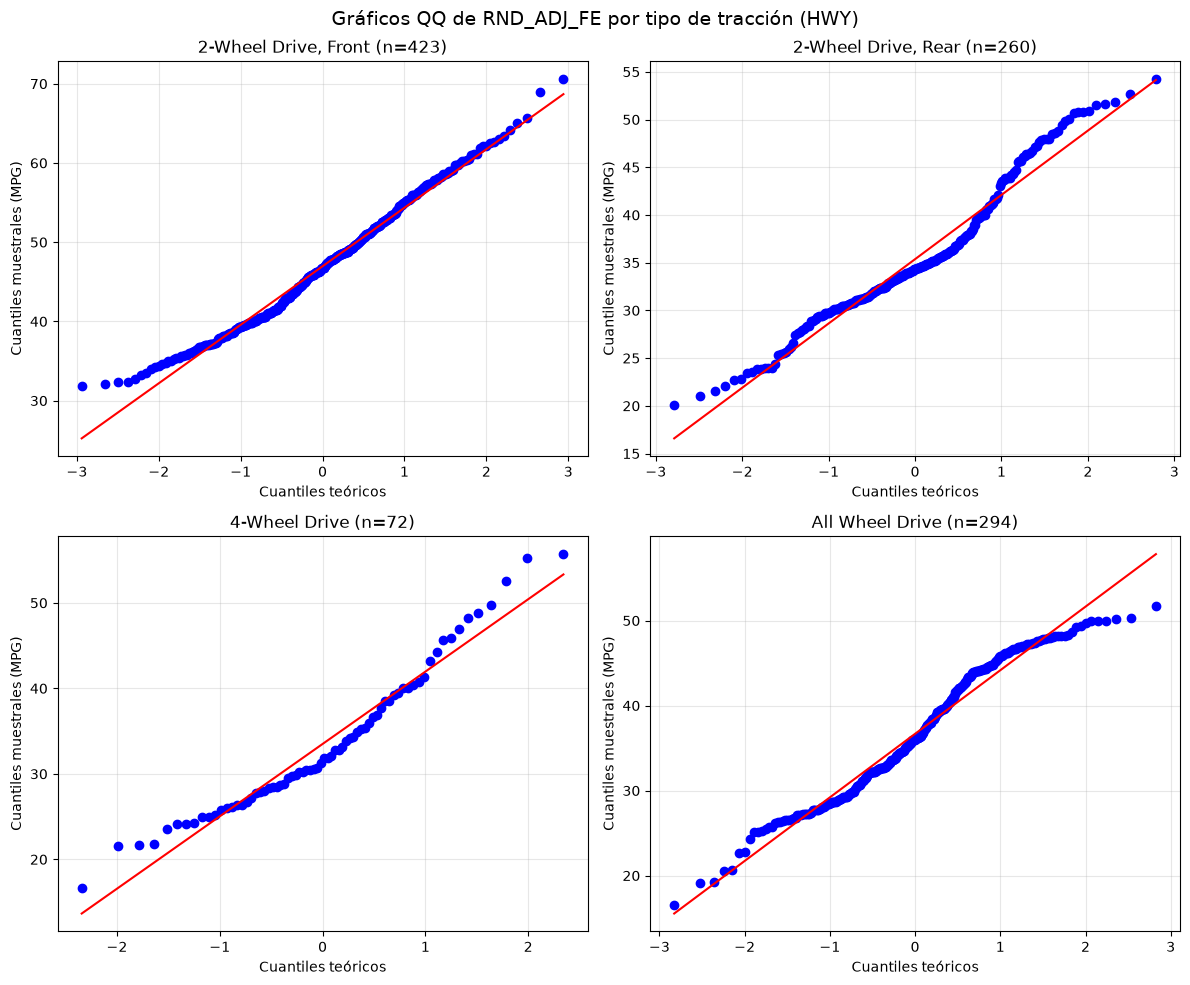

In [1165]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

FE = "RND_ADJ_FE"
TRACCION = "Drive System Description"

grupos = list(data_HWY.groupby(TRACCION)[FE])
n_grupos = len(grupos)
ncols = 2
nrows = int(np.ceil(n_grupos / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 5 * nrows))
axes = np.atleast_1d(axes).flatten()

for ax, (traccion, valores) in zip(axes, grupos):
    valores = valores.dropna()
    stats.probplot(valores, dist="norm", plot=ax)
    ax.set_title(f"{traccion} (n={len(valores)})")
    ax.set_xlabel("Cuantiles teóricos")
    ax.set_ylabel("Cuantiles muestrales (MPG)")
    ax.grid(alpha=0.3)

for ax in axes[n_grupos:]:
    ax.set_visible(False)

fig.suptitle("Gráficos QQ de RND_ADJ_FE por tipo de tracción (HWY)", fontsize=14)
plt.tight_layout()
plt.show()

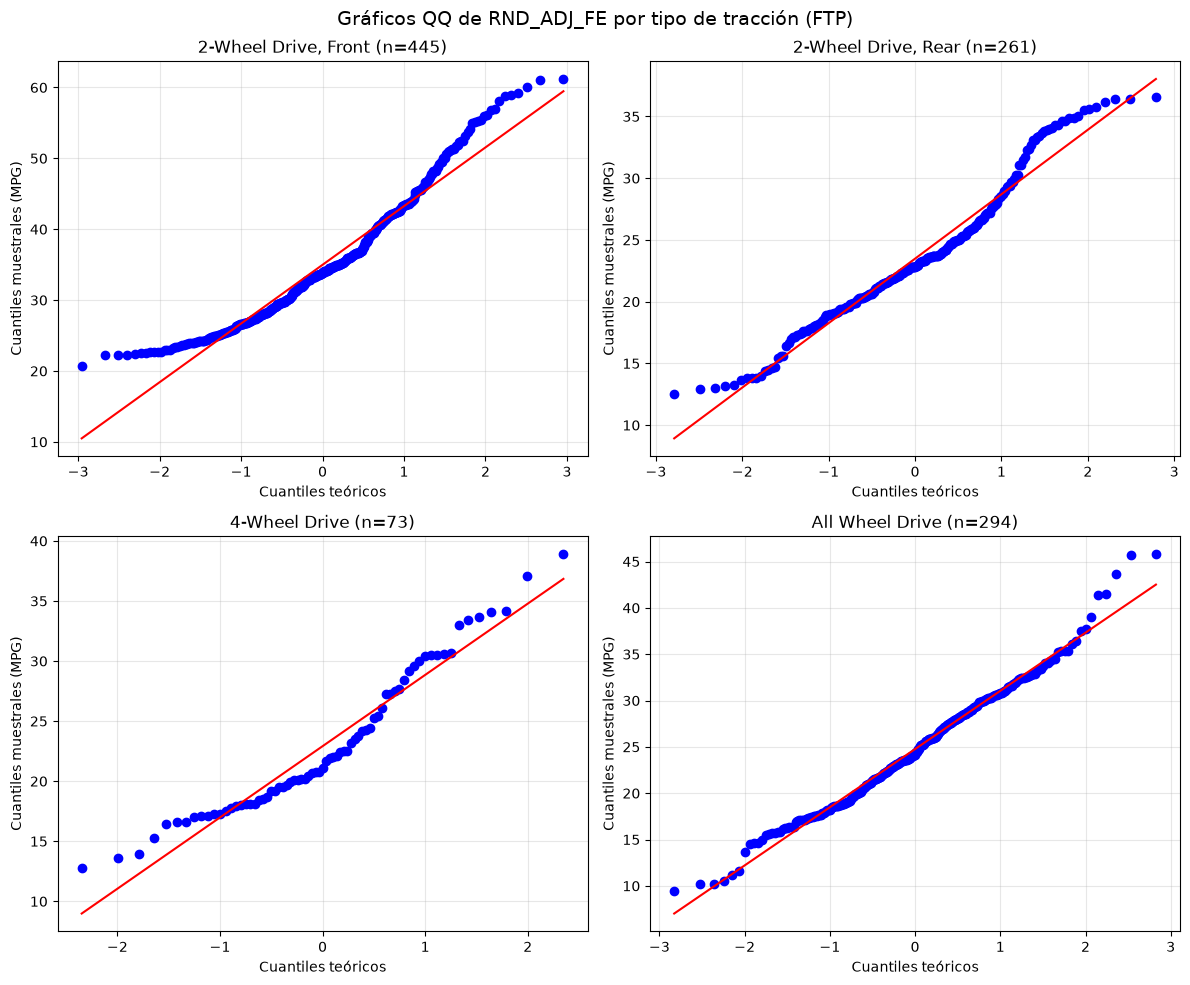

In [1166]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

FE = "RND_ADJ_FE"
TRACCION = "Drive System Description"

grupos = list(data_FTP.groupby(TRACCION)[FE])
n_grupos = len(grupos)
ncols = 2
nrows = int(np.ceil(n_grupos / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 5 * nrows))
axes = np.atleast_1d(axes).flatten()

for ax, (traccion, valores) in zip(axes, grupos):
    valores = valores.dropna()
    stats.probplot(valores, dist="norm", plot=ax)
    ax.set_title(f"{traccion} (n={len(valores)})")
    ax.set_xlabel("Cuantiles teóricos")
    ax.set_ylabel("Cuantiles muestrales (MPG)")
    ax.grid(alpha=0.3)

for ax in axes[n_grupos:]:
    ax.set_visible(False)

fig.suptitle("Gráficos QQ de RND_ADJ_FE por tipo de tracción (FTP)", fontsize=14)
plt.tight_layout()
plt.show()

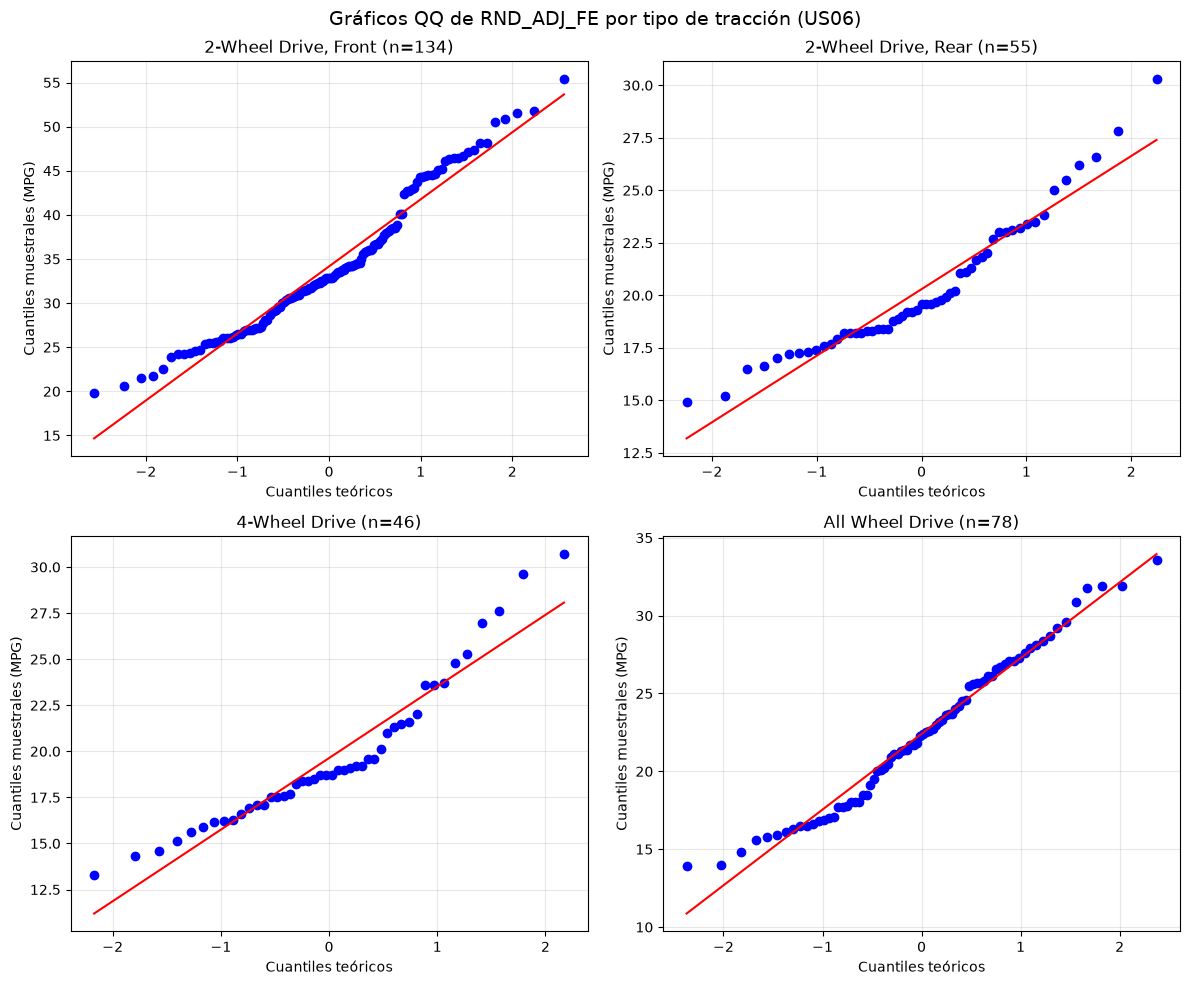

In [1167]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

FE = "RND_ADJ_FE"
TRACCION = "Drive System Description"

grupos = list(data_US06.groupby(TRACCION)[FE])
n_grupos = len(grupos)
ncols = 2
nrows = int(np.ceil(n_grupos / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 5 * nrows))
axes = np.atleast_1d(axes).flatten()

for ax, (traccion, valores) in zip(axes, grupos):
    valores = valores.dropna()
    stats.probplot(valores, dist="norm", plot=ax)
    ax.set_title(f"{traccion} (n={len(valores)})")
    ax.set_xlabel("Cuantiles teóricos")
    ax.set_ylabel("Cuantiles muestrales (MPG)")
    ax.grid(alpha=0.3)

for ax in axes[n_grupos:]:
    ax.set_visible(False)

fig.suptitle("Gráficos QQ de RND_ADJ_FE por tipo de tracción (US06)", fontsize=14)
plt.tight_layout()
plt.show()

### Finalmente como no se cumplieron los supuestos necesarios para realizar ANOVA, procederemos a llevar a cabo Kruskall-Wallis

In [1168]:
alpha = 0.05  # Nivel de significancia

fwd_FE = data_HWY[data_HWY["Drive System Description"] == "2-Wheel Drive, Front"]['RND_ADJ_FE']
rwd_FE = data_HWY[data_HWY["Drive System Description"] == "2-Wheel Drive, Rear"]['RND_ADJ_FE']
awd_FE = data_HWY[data_HWY["Drive System Description"] == "All Wheel Drive"]['RND_ADJ_FE']
four_wd_FE = data_HWY[data_HWY["Drive System Description"] == "4-Wheel Drive"]['RND_ADJ_FE']
print("TESTS DE HIPOTESIS MEDIANTE KRUSKALL-WALLIS")
print(" ")
stat, p = stats.kruskal(fwd_FE, rwd_FE, awd_FE, four_wd_FE)
print(f"Test de Kruskal-Wallis para Economia de combustible segun traccion (HWY): Estadístico={stat:.3f}, p-valor={p:.3f}")
if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en la emision de CO2 segun el tipo de transmision")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en la emision de CO2 segun el tipo de transmision")
print("========================================================================================")

fwd_FE = data_FTP[data_FTP["Drive System Description"] == "2-Wheel Drive, Front"]['RND_ADJ_FE']
rwd_FE = data_FTP[data_FTP["Drive System Description"] == "2-Wheel Drive, Rear"]['RND_ADJ_FE']
awd_FE = data_FTP[data_FTP["Drive System Description"] == "All Wheel Drive"]['RND_ADJ_FE']
four_wd_FE = data_FTP[data_FTP["Drive System Description"] == "4-Wheel Drive"]['RND_ADJ_FE']

stat, p = stats.kruskal(fwd_FE, rwd_FE, awd_FE, four_wd_FE)
print(f"Test de Kruskal-Wallis para Economia de combustible segun traccion (FTP): Estadístico={stat:.3f}, p-valor={p:.3f}")
if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en la emision de CO2 segun el tipo de transmision")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en la emision de CO2 segun el tipo de transmision")
print("========================================================================================")
fwd_FE = data_US06[data_US06["Drive System Description"] == "2-Wheel Drive, Front"]['RND_ADJ_FE']
rwd_FE = data_US06[data_US06["Drive System Description"] == "2-Wheel Drive, Rear"]['RND_ADJ_FE']
awd_FE = data_US06[data_US06["Drive System Description"] == "All Wheel Drive"]['RND_ADJ_FE']
four_wd_FE = data_US06[data_US06["Drive System Description"] == "4-Wheel Drive"]['RND_ADJ_FE']

stat, p = stats.kruskal(fwd_FE, rwd_FE, awd_FE, four_wd_FE)
print(f"Test de Kruskal-Wallis para Economia de combustible segun traccion (US06): Estadístico={stat:.3f}, p-valor={p:.3f}")
if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en la emision de CO2 segun el tipo de transmision")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en la emision de CO2 segun el tipo de transmision")

TESTS DE HIPOTESIS MEDIANTE KRUSKALL-WALLIS
 
Test de Kruskal-Wallis para Economia de combustible segun traccion (HWY): Estadístico=385.577, p-valor=0.000
Se rechaza la hipótesis nula.
Existe una diferencia significativa en la emision de CO2 segun el tipo de transmision
Test de Kruskal-Wallis para Economia de combustible segun traccion (FTP): Estadístico=427.180, p-valor=0.000
Se rechaza la hipótesis nula.
Existe una diferencia significativa en la emision de CO2 segun el tipo de transmision
Test de Kruskal-Wallis para Economia de combustible segun traccion (US06): Estadístico=188.172, p-valor=0.000
Se rechaza la hipótesis nula.
Existe una diferencia significativa en la emision de CO2 segun el tipo de transmision


# CONCLUSION:
## El p-valor < 0.05 como resultado en cada uno de los tests llevados a cabo indica que existe evidencia estadistica suficiente para rechazar la hipotesis nula (H0). Esto puede afirmar la hipotesis alternativa(H1). De esta manera se puede afirmar, que efectivamente, existen diferencias en la economia de combustible entre los vehiculos a combustion segun su tipo de traccion. 